In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive



 Running Cirrhosis Prediction with SHAP Explainability...

 Test Accuracy: 0.84

 Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.93      0.86        30
           1       0.90      0.73      0.81        26

    accuracy                           0.84        56
   macro avg       0.85      0.83      0.84        56
weighted avg       0.85      0.84      0.84        56


 Running SHAP Explainability...


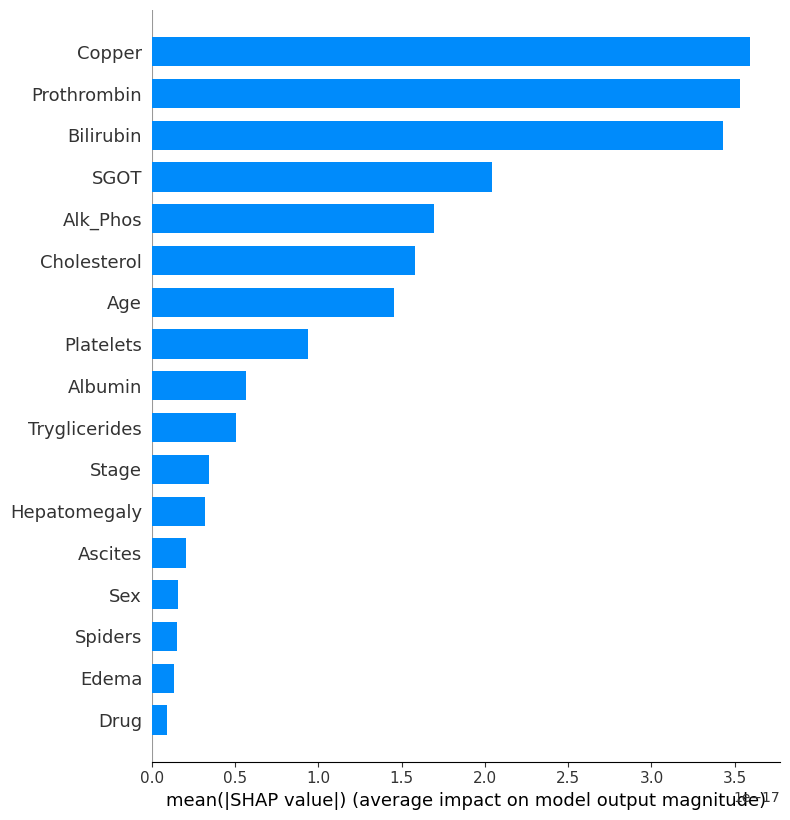

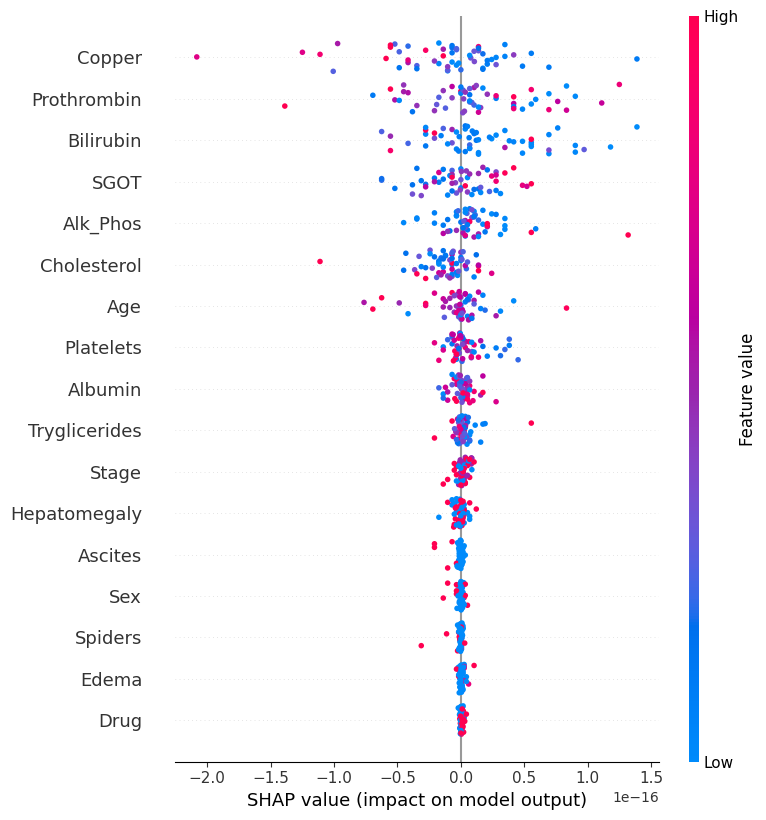


 Top 5 Most Important Features (SHAP):
- Copper: contributes avg. 0.0000 to prediction
- Prothrombin: contributes avg. 0.0000 to prediction
- Bilirubin: contributes avg. 0.0000 to prediction
- SGOT: contributes avg. 0.0000 to prediction
- Alk_Phos: contributes avg. 0.0000 to prediction


In [ ]:
print("\n Running Cirrhosis Prediction with SHAP Explainability...")

# === Imports ===
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

# === Load Dataset ===
# data_path = r"E:\Datasets\PBC dataset.csv"  # Update path as needed
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# === Preprocessing ===

# Drop irrelevant columns
df = df.drop(columns=['ID', 'N_Days'], errors='ignore')

# Convert target to binary: 1 = Death ('D'), 0 = Alive/Censored ('C', 'CL')
df['Status'] = df['Status'].map(lambda x: 1 if x == 'D' else 0)

# Encode categorical features
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
for col in categorical_cols:
    df[col] = df[col].astype(str)
    df[col] = LabelEncoder().fit_transform(df[col])

# Drop rows with missing values
df.dropna(inplace=True)

# Define features and target
X = df.drop('Status', axis=1)
y = df['Status']

# === Train-Test Split ===
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# === Train Random Forest ===
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# === Evaluate Model ===
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"\n Test Accuracy: {acc:.2f}")
print("\n Classification Report:\n", classification_report(y_test, y_pred))

# === SHAP Explainability ===
print("\n Running SHAP Explainability...")

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Use class 1 (death)
shap_vals = shap_values[1] if isinstance(shap_values, list) else shap_values

# Remove bias column if present
if shap_vals.shape[1] == X_test.shape[1] + 1:
    shap_vals = shap_vals[:, :-1]

# Reduce 3D SHAP values to 2D
if len(shap_vals.shape) == 3:
    shap_vals = np.mean(shap_vals, axis=2)

# SHAP summary plots
shap.summary_plot(shap_vals, X_test, plot_type="bar", show=True)
shap.summary_plot(shap_vals, X_test, show=True)

# Feature impact from SHAP
mean_abs_shap = np.abs(shap_vals).mean(axis=0)
feature_impact = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP value|": mean_abs_shap
}).sort_values(by="Mean |SHAP value|", ascending=False)

print("\n Top 5 Most Important Features (SHAP):")
for _, row in feature_impact.head(5).iterrows():
    print(f"- {row['Feature']}: contributes avg. {row['Mean |SHAP value|']:.4f} to prediction")



 Accuracy: 0.84
              precision    recall  f1-score   support

           0       0.80      0.93      0.86        30
           1       0.90      0.73      0.81        26

    accuracy                           0.84        56
   macro avg       0.85      0.83      0.84        56
weighted avg       0.85      0.84      0.84        56



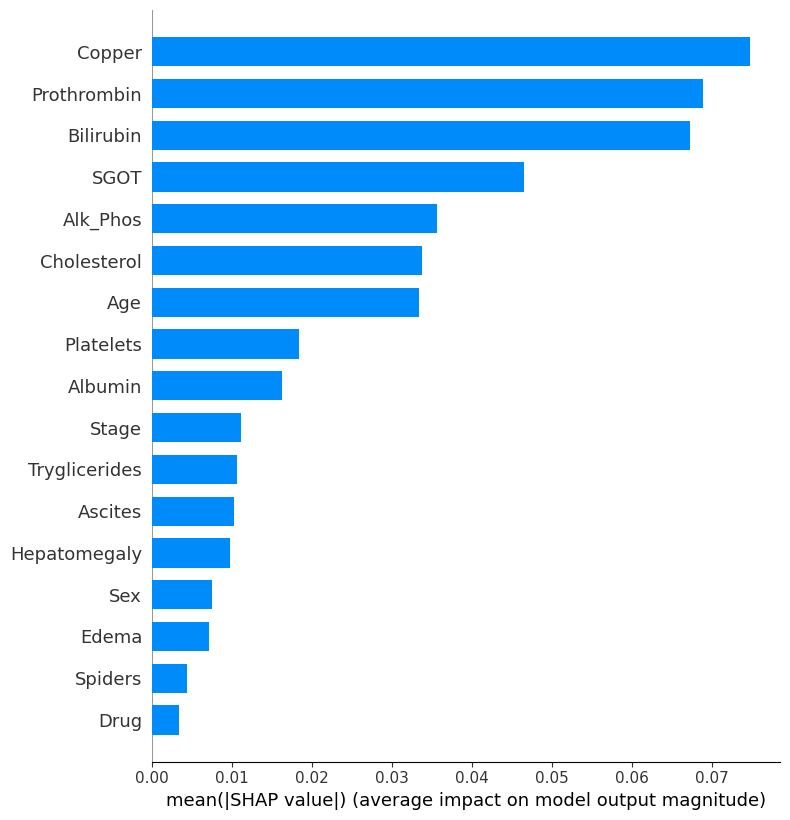

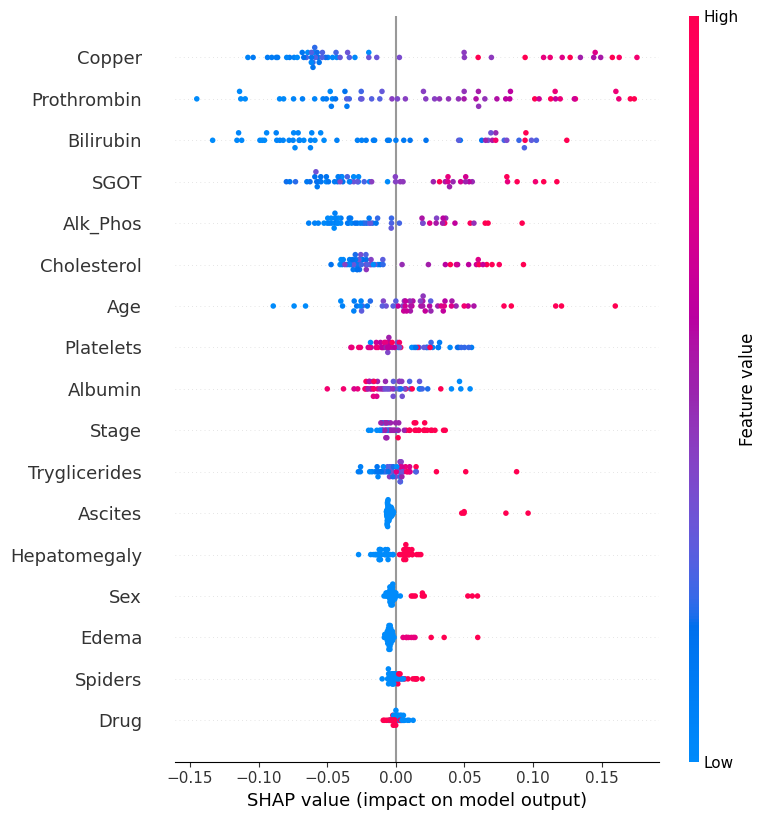


 Fidelity (Comprehensiveness): 0.0032
Sparsity (90% SHAP coverage): 9 out of 17
 Consistency (original vs shuffled SHAP): 0.5371
 Sufficiency (top 5 only): 0.3734

 Top 5 Most Important Features (SHAP):
- Copper: contributes avg. 0.0747
- Prothrombin: contributes avg. 0.0688
- Bilirubin: contributes avg. 0.0672
- SGOT: contributes avg. 0.0464
- Alk_Phos: contributes avg. 0.0357


In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

# === Load Dataset ===
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# === Preprocessing ===
df = df.drop(columns=['ID', 'N_Days'], errors='ignore')
df['Status'] = df['Status'].map(lambda x: 1 if x == 'D' else 0)
for col in df.select_dtypes(include=['object']).columns:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))
df.dropna(inplace=True)

X = df.drop('Status', axis=1)
y = df['Status']

# === Train-Test Split ===
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# === Train Model ===
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# === Evaluate ===
print(f"\n Accuracy: {accuracy_score(y_test, model.predict(X_test)):.2f}")
print(classification_report(y_test, model.predict(X_test)))

# === SHAP ===
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Handle different SHAP output shapes for binary classification:
if isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    # shap_values shape is (samples, features, classes), pick class 1
    shap_vals = shap_values[:, :, 1]
elif isinstance(shap_values, list):
    # shap_values is a list per class, pick class 1
    shap_vals = shap_values[1]
else:
    shap_vals = shap_values

# Confirm final shape matches X_test
assert shap_vals.shape == X_test.shape, f"SHAP shape {shap_vals.shape} != X_test {X_test.shape}"

# === SHAP Summary Plots ===
shap.summary_plot(shap_vals, X_test, plot_type="bar", show=True)
shap.summary_plot(shap_vals, X_test, show=True)

# === SHAP Metrics ===
abs_vals = np.abs(shap_vals)
mean_abs_vals = abs_vals.mean(axis=0)

# --- Fidelity ---
top_k = 5
top_indices = np.argsort(mean_abs_vals)[::-1][:top_k]
top_features = X_test.columns[top_indices]

X_masked = X_test.copy()
X_masked.loc[:, ~X_masked.columns.isin(top_features)] = 0
fidelity = (model.predict_proba(X_test)[:, 1] - model.predict_proba(X_masked)[:, 1]).mean()
print(f"\n Fidelity (Comprehensiveness): {fidelity:.4f}")

# --- Sparsity ---
cumsum_sorted = np.cumsum(np.sort(abs_vals, axis=1)[:, ::-1], axis=1)
total = abs_vals.sum(axis=1)
num_needed = (cumsum_sorted < (0.9 * total[:, None])).sum(axis=1) + 1
print(f"Sparsity (90% SHAP coverage): {int(num_needed.mean())} out of {X_test.shape[1]}")

# --- Consistency ---
X_shuffled = X_test.sample(frac=1, random_state=42)
shuffled_vals = explainer.shap_values(X_shuffled)
if isinstance(shuffled_vals, np.ndarray) and shuffled_vals.ndim == 3:
    shuffled_vals = shuffled_vals[:, :, 1]
elif isinstance(shuffled_vals, list):
    shuffled_vals = shuffled_vals[1]

consistency = np.corrcoef(abs_vals.flatten(), np.abs(shuffled_vals).flatten())[0, 1]
print(f" Consistency (original vs shuffled SHAP): {consistency:.4f}")

# --- Sufficiency ---
X_top_only = X_test.copy()
X_top_only.loc[:, ~X_top_only.columns.isin(top_features)] = 0
sufficiency = model.predict_proba(X_top_only)[:, 1].mean()
print(f" Sufficiency (top {top_k} only): {sufficiency:.4f}")

# === Top 5 Features ===
impact_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP|": mean_abs_vals
}).sort_values(by="Mean |SHAP|", ascending=False)

print("\n Top 5 Most Important Features (SHAP):")
for _, row in impact_df.head(5).iterrows():
    print(f"- {row['Feature']}: contributes avg. {row['Mean |SHAP|']:.4f}")


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
!pip install lime
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report
from lime.lime_tabular import LimeTabularExplainer
from sklearn.utils import shuffle

# === Load Dataset ===
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# === Preprocessing ===
df = df.drop(columns=['ID', 'N_Days'], errors='ignore')
df['Status'] = df['Status'].map(lambda x: 1 if x == 'D' else 0)
for col in df.select_dtypes(include=['object']).columns:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))
df.dropna(inplace=True)

X = df.drop('Status', axis=1)
y = df['Status']
feature_names = X.columns.tolist()

# === Train-Test Split ===
X_train, X_test, y_train, y_test = train_test_split(
    X.values, y.values, test_size=0.2, random_state=42
)

# === Train Model ===
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# === Evaluate ===
print(f"\n Accuracy: {accuracy_score(y_test, model.predict(X_test)):.2f}")
print(classification_report(y_test, model.predict(X_test)))

# === LIME ===
explainer = LimeTabularExplainer(
    training_data=X_train,
    feature_names=feature_names,
    class_names=["No Cirrhosis", "Cirrhosis"],
    mode="classification",
    discretize_continuous=True
)

# Explain one instance to show structure
idx = 0
exp = explainer.explain_instance(X_test[idx], model.predict_proba, num_features=len(feature_names))
exp.show_in_notebook(show_table=True)

# === Feature Importance (LIME Average) ===
lime_vals = np.zeros((X_test.shape[0], X_test.shape[1]))

for i in range(X_test.shape[0]):
    exp = explainer.explain_instance(X_test[i], model.predict_proba, num_features=len(feature_names))
    for feat, val in exp.as_list():
        feat_name = feat.split(' ')[0]
        try:
            idx_feat = feature_names.index(feat_name)
            lime_vals[i, idx_feat] = val
        except ValueError:
            pass  # feature name not found

abs_lime = np.abs(lime_vals)
mean_abs_vals = abs_lime.mean(axis=0)

# === Fidelity ===
top_k = 5
top_indices = np.argsort(mean_abs_vals)[::-1][:top_k]
top_features = [feature_names[i] for i in top_indices]

X_masked = pd.DataFrame(X_test, columns=feature_names)
X_masked.loc[:, ~X_masked.columns.isin(top_features)] = 0
fidelity = (model.predict_proba(X_test)[:, 1] - model.predict_proba(X_masked.values)[:, 1]).mean()
print(f"\n Fidelity (Comprehensiveness): {fidelity:.4f}")

# === Sparsity ===
cumsum_sorted = np.cumsum(np.sort(abs_lime, axis=1)[:, ::-1], axis=1)
total = abs_lime.sum(axis=1)
num_needed = (cumsum_sorted < (0.9 * total[:, None])).sum(axis=1) + 1
print(f" Sparsity (90% LIME coverage): {int(num_needed.mean())} out of {X_test.shape[1]}")

# === Consistency ===
X_shuffled = shuffle(X_test, random_state=42)
shuffled_vals = np.zeros_like(lime_vals)
for i in range(X_shuffled.shape[0]):
    exp = explainer.explain_instance(X_shuffled[i], model.predict_proba, num_features=len(feature_names))
    for feat, val in exp.as_list():
        feat_name = feat.split(' ')[0]
        try:
            idx_feat = feature_names.index(feat_name)
            shuffled_vals[i, idx_feat] = val
        except ValueError:
            pass

consistency = np.corrcoef(abs_lime.flatten(), np.abs(shuffled_vals).flatten())[0, 1]
print(f"Consistency (original vs shuffled LIME): {consistency:.4f}")

# === Sufficiency ===
X_top_only = pd.DataFrame(X_test, columns=feature_names)
X_top_only.loc[:, ~X_top_only.columns.isin(top_features)] = 0
sufficiency = model.predict_proba(X_top_only.values)[:, 1].mean()
print(f" Sufficiency (top {top_k} only): {sufficiency:.4f}")

# === Top 5 Features ===
impact_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean |LIME|": mean_abs_vals
}).sort_values(by="Mean |LIME|", ascending=False)

print("\n Top 5 Most Important Features (LIME):")
for _, row in impact_df.head(5).iterrows():
    print(f"- {row['Feature']}: contributes avg. {row['Mean |LIME|']:.4f}")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=8c65716c717875ce464c625aaec68082c9c6576ea8e7b1dea170ec98143f683d
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime

 Accuracy: 0.84
              precision    recall  f1-score   support

           0       0.80      0.93      0.86        30
           1       0.90      0.73      0.81        26

    accuracy                           0.84        56
   macro avg       0.85      0.83      0.84        56
weighted avg       0.85      0.84      0.84        56




 Fidelity (Comprehensiveness): 0.0000
 Sparsity (90% LIME coverage): 7 out of 17
Consistency (original vs shuffled LIME): 0.3744
 Sufficiency (top 5 only): 0.4171

 Top 5 Most Important Features (LIME):
- Ascites: contributes avg. 0.0903
- Copper: contributes avg. 0.0699
- Prothrombin: contributes avg. 0.0671
- Bilirubin: contributes avg. 0.0580
- Alk_Phos: contributes avg. 0.0451


In [5]:
#SVM


Accuracy: 0.86
              precision    recall  f1-score   support

           0       0.79      1.00      0.88        30
           1       1.00      0.69      0.82        26

    accuracy                           0.86        56
   macro avg       0.89      0.85      0.85        56
weighted avg       0.89      0.86      0.85        56



/usr/local/lib/python3.12/dist-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)


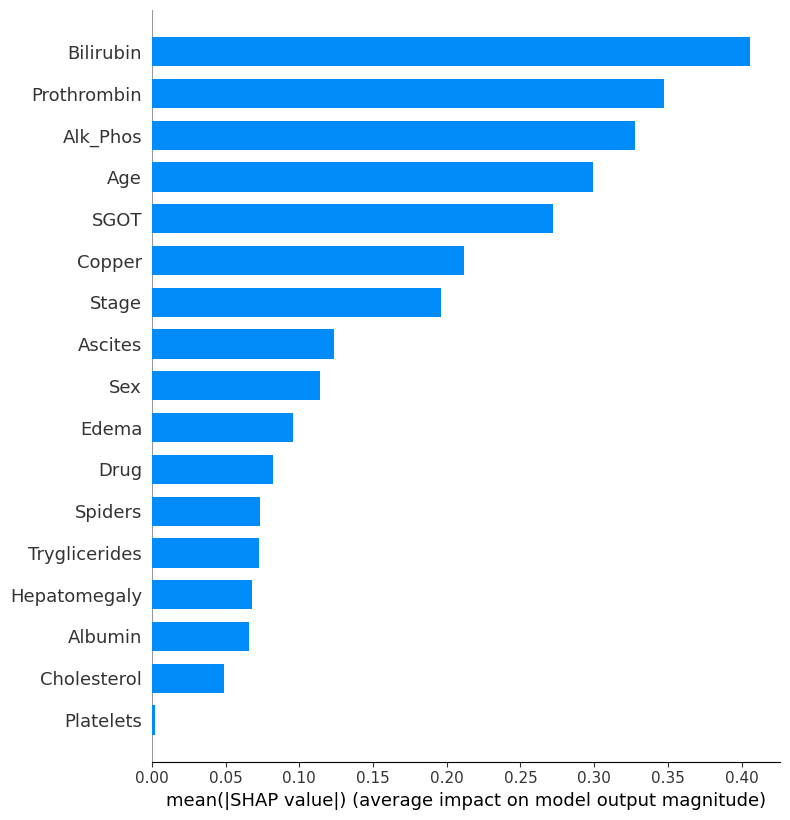

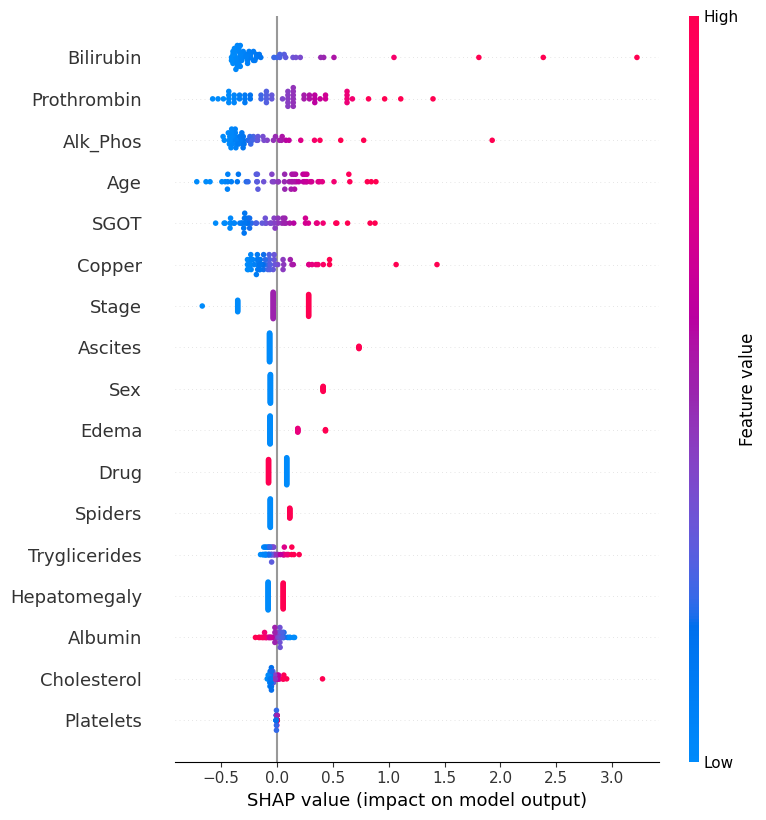


 Fidelity (Comprehensiveness): 0.0084
Sparsity (90% SHAP coverage): 10 out of 17
Consistency (original vs shuffled SHAP): 0.3243
Sufficiency (top 5 only): 0.3714

Top 5 Most Important Features (SHAP):
- Bilirubin: contributes avg. 0.4057
- Prothrombin: contributes avg. 0.3470
- Alk_Phos: contributes avg. 0.3275
- Age: contributes avg. 0.2989
- SGOT: contributes avg. 0.2720


In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# === Load Dataset ===
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# === Preprocessing ===
df = df.drop(columns=['ID', 'N_Days'], errors='ignore')
df['Status'] = df['Status'].map(lambda x: 1 if x == 'D' else 0)
for col in df.select_dtypes(include=['object']).columns:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))
df.dropna(inplace=True)

X = df.drop('Status', axis=1)
y = df['Status']
feature_names = X.columns.tolist()

# === Scale Features ===
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# === Train-Test Split ===
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y.values, test_size=0.2, random_state=42
)

# === Train Model ===
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

# === Evaluate ===
print(f"\nAccuracy: {accuracy_score(y_test, model.predict(X_test)):.2f}")
print(classification_report(y_test, model.predict(X_test)))

# === SHAP ===
explainer = shap.LinearExplainer(model, X_train, feature_perturbation="interventional")
shap_values = explainer.shap_values(X_test)

# If list (multi-class), take class 1 (Death)
if isinstance(shap_values, list):
    shap_vals = shap_values[1]
else:
    shap_vals = shap_values

# Confirm final shape
assert shap_vals.shape == X_test.shape, f"SHAP shape {shap_vals.shape} != X_test {X_test.shape}"

# === SHAP Summary Plots ===
shap.summary_plot(shap_vals, features=X_test, feature_names=feature_names, plot_type="bar")
shap.summary_plot(shap_vals, features=X_test, feature_names=feature_names)

# === SHAP Metrics ===
abs_vals = np.abs(shap_vals)
mean_abs_vals = abs_vals.mean(axis=0)

# --- Fidelity ---
top_k = 5
top_indices = np.argsort(mean_abs_vals)[::-1][:top_k]
top_features = [feature_names[i] for i in top_indices]

X_df = pd.DataFrame(X_test, columns=feature_names)
X_masked = X_df.copy()
X_masked.loc[:, ~X_masked.columns.isin(top_features)] = 0
fidelity = (model.predict_proba(X_test)[:, 1] - model.predict_proba(X_masked.values)[:, 1]).mean()
print(f"\n Fidelity (Comprehensiveness): {fidelity:.4f}")

# --- Sparsity ---
cumsum_sorted = np.cumsum(np.sort(abs_vals, axis=1)[:, ::-1], axis=1)
total = abs_vals.sum(axis=1)
num_needed = (cumsum_sorted < (0.9 * total[:, None])).sum(axis=1) + 1
print(f"Sparsity (90% SHAP coverage): {int(num_needed.mean())} out of {X_test.shape[1]}")

# --- Consistency ---
X_shuffled = X_df.sample(frac=1, random_state=42).values
shuffled_vals = explainer.shap_values(X_shuffled)[1] if isinstance(shap_values, list) else explainer.shap_values(X_shuffled)
consistency = np.corrcoef(abs_vals.flatten(), np.abs(shuffled_vals).flatten())[0, 1]
print(f"Consistency (original vs shuffled SHAP): {consistency:.4f}")

# --- Sufficiency ---
X_top_only = X_df.copy()
X_top_only.loc[:, ~X_top_only.columns.isin(top_features)] = 0
sufficiency = model.predict_proba(X_top_only.values)[:, 1].mean()
print(f"Sufficiency (top {top_k} only): {sufficiency:.4f}")

# === Top 5 Features ===
impact_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean |SHAP|": mean_abs_vals
}).sort_values(by="Mean |SHAP|", ascending=False)

print("\nTop 5 Most Important Features (SHAP):")
for _, row in impact_df.head(5).iterrows():
    print(f"- {row['Feature']}: contributes avg. {row['Mean |SHAP|']:.4f}")


In [7]:
#SVM with LIME


Accuracy: 0.86
              precision    recall  f1-score   support

           0       0.79      1.00      0.88        30
           1       1.00      0.69      0.82        26

    accuracy                           0.86        56
   macro avg       0.89      0.85      0.85        56
weighted avg       0.89      0.86      0.85        56


LIME Explanations for 3 test samples:

Sample #0
True Label: Death
Predicted: Alive


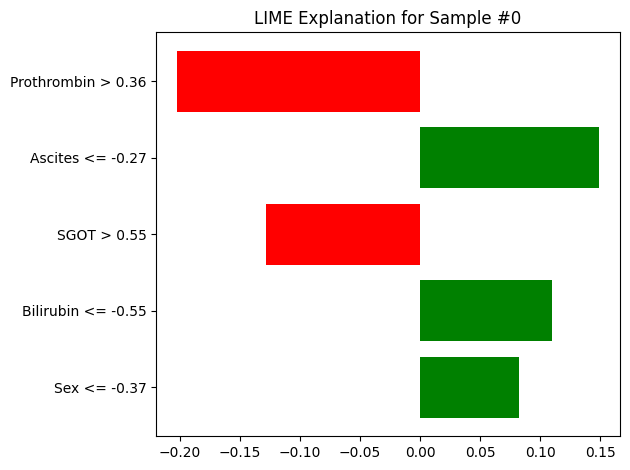


Sample #1
True Label: Death
Predicted: Alive


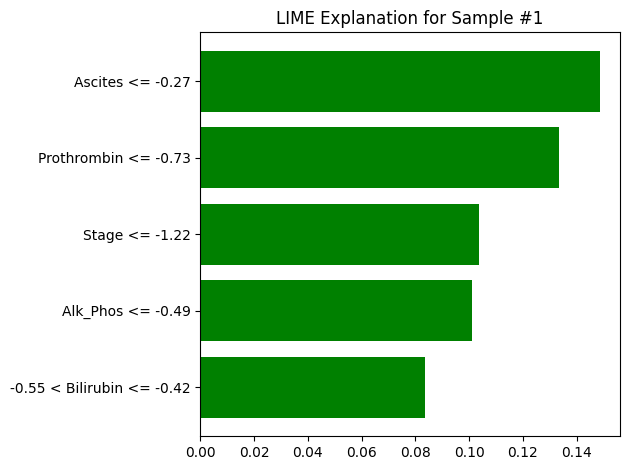


Sample #2
True Label: Death
Predicted: Death


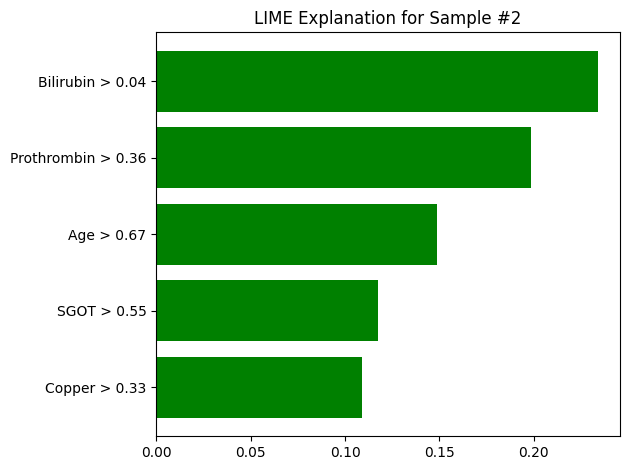

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import lime
import lime.lime_tabular

# === Load Dataset ===
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# === Preprocessing ===
df = df.drop(columns=['ID', 'N_Days'], errors='ignore')
df['Status'] = df['Status'].map(lambda x: 1 if x == 'D' else 0)
for col in df.select_dtypes(include=['object']).columns:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))
df.dropna(inplace=True)

X = df.drop('Status', axis=1)
y = df['Status']
feature_names = X.columns.tolist()

# === Scale Features ===
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# === Train-Test Split ===
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y.values, test_size=0.2, random_state=42
)

# === Train Logistic Regression ===
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

# === Evaluate ===
print(f"\nAccuracy: {accuracy_score(y_test, model.predict(X_test)):.2f}")
print(classification_report(y_test, model.predict(X_test)))

# === LIME Explainer ===
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train,
    feature_names=feature_names,
    class_names=["No Cirrhosis", "Cirrhosis"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# === LIME Explanation ===
num_samples_to_explain = 3
print(f"\nLIME Explanations for {num_samples_to_explain} test samples:")

for i in range(num_samples_to_explain):
    idx = i
    sample = X_test[idx]
    predicted_label = model.predict([sample])[0]

    exp = explainer.explain_instance(
        sample,
        model.predict_proba,
        num_features=5,
        top_labels=1
    )

    print(f"\nSample #{idx}")
    print(f"True Label: {['Alive', 'Death'][y_test[idx]]}")
    print(f"Predicted: {['Alive', 'Death'][predicted_label]}")

    # Show explanation in notebook (optional in Jupyter)
    exp.show_in_notebook(show_table=True)

    # Plot explanation
    fig = exp.as_pyplot_figure(label=predicted_label)
    plt.title(f"LIME Explanation for Sample #{idx}")
    plt.tight_layout()
    plt.show()



Accuracy: 0.86
              precision    recall  f1-score   support

           0       0.79      1.00      0.88        30
           1       1.00      0.69      0.82        26

    accuracy                           0.86        56
   macro avg       0.89      0.85      0.85        56
weighted avg       0.89      0.86      0.85        56


LIME Explanations for 3 test samples:

Sample #0
True Label: Death
Predicted: Alive


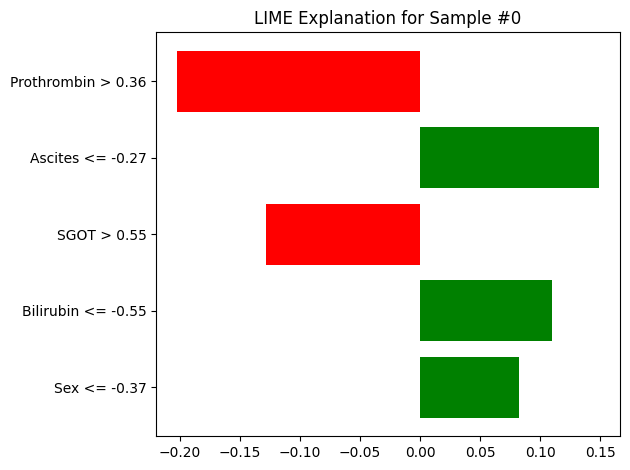


Sample #1
True Label: Death
Predicted: Alive


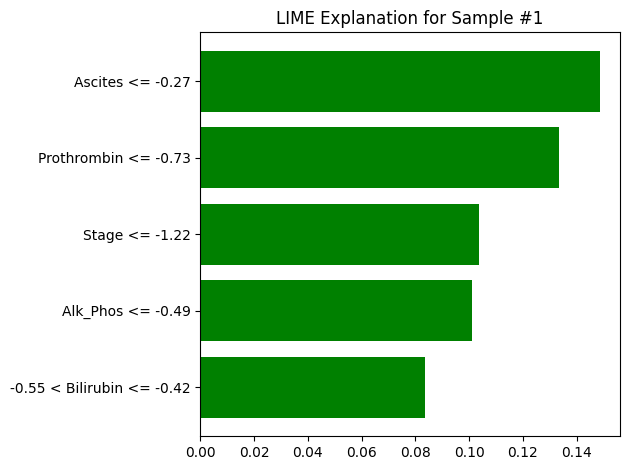


Sample #2
True Label: Death
Predicted: Death


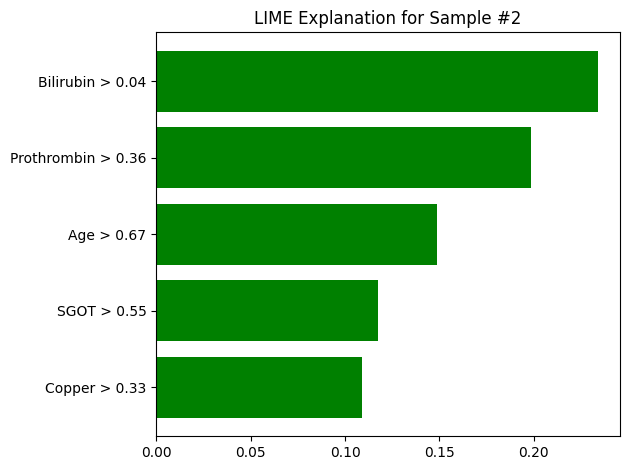

LIME Explainer: 100%|██████████| 56/56 [00:12<00:00,  4.56it/s]



Fidelity (Comprehensiveness): -0.0013
Sparsity (90% LIME coverage): 10 out of 17


PermutationExplainer explainer: 100%|██████████| 56/56 [00:14<00:00,  3.86it/s]

Consistency (original vs shuffled LIME): 0.5838
Sufficiency (top 5 only): 0.3812

Top 5 Most Important Features (LIME):
- Ascites: contributes avg. 0.1420
- Bilirubin: contributes avg. 0.1211
- Prothrombin: contributes avg. 0.1145
- Alk_Phos: contributes avg. 0.1142
- Age: contributes avg. 0.0812


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import lime
import lime.lime_tabular
from tqdm import tqdm

# === Load Dataset ===
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# === Preprocessing ===
df = df.drop(columns=['ID', 'N_Days'], errors='ignore')
df['Status'] = df['Status'].map(lambda x: 1 if x == 'D' else 0)
for col in df.select_dtypes(include=['object']).columns:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))
df.dropna(inplace=True)

X = df.drop('Status', axis=1)
y = df['Status']
feature_names = X.columns.tolist()

# === Scale Features ===
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# === Train-Test Split ===
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y.values, test_size=0.2, random_state=42
)

# === Train Logistic Regression ===
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

# === Evaluate ===
print(f"\nAccuracy: {accuracy_score(y_test, model.predict(X_test)):.2f}")
print(classification_report(y_test, model.predict(X_test)))

# === LIME Explainer ===
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train,
    feature_names=feature_names,
    class_names=["Alive", "Death"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# === LIME Explanation (3 samples) ===
print("\nLIME Explanations for 3 test samples:")
for i in range(3):
    sample = X_test[i]
    predicted_label = model.predict([sample])[0]

    exp = explainer.explain_instance(
        sample,
        model.predict_proba,
        num_features=5,
        top_labels=1
    )

    print(f"\nSample #{i}")
    print(f"True Label: {['Alive', 'Death'][y_test[i]]}")
    print(f"Predicted: {['Alive', 'Death'][predicted_label]}")

    fig = exp.as_pyplot_figure(label=predicted_label)
    plt.title(f"LIME Explanation for Sample #{i}")
    plt.tight_layout()
    plt.show()

# === LIME Global Metric Collection ===
lime_explanations = []
abs_weights = []

for i in tqdm(range(len(X_test)), desc="LIME Explainer"):
    sample = X_test[i]
    predicted_label = model.predict([sample])[0]

    exp = explainer.explain_instance(
        sample,
        model.predict_proba,
        num_features=len(feature_names),
        top_labels=1
    )
    local_exp = dict(exp.local_exp[predicted_label])
    weights = np.array([local_exp.get(i, 0) for i in range(len(feature_names))])
    lime_explanations.append(weights)
    abs_weights.append(np.abs(weights))

lime_explanations = np.array(lime_explanations)
abs_weights = np.array(abs_weights)

mean_abs_vals = abs_weights.mean(axis=0)
top_k = 5
top_indices = np.argsort(mean_abs_vals)[::-1][:top_k]
top_features = np.array(feature_names)[top_indices]

# === Fidelity (Comprehensiveness) ===
X_masked = X_test.copy()
X_masked[:, ~np.isin(feature_names, top_features)] = 0
original_probs = model.predict_proba(X_test)[:, 1]
masked_probs = model.predict_proba(X_masked)[:, 1]
fidelity = np.mean(original_probs - masked_probs)
print(f"\nFidelity (Comprehensiveness): {fidelity:.4f}")

# === Sparsity (90% LIME Coverage) ===
cumsum_sorted = np.cumsum(np.sort(abs_weights, axis=1)[:, ::-1], axis=1)
total = abs_weights.sum(axis=1)
num_needed = (cumsum_sorted < (0.9 * total[:, None])).sum(axis=1) + 1
print(f"Sparsity (90% LIME coverage): {int(num_needed.mean())} out of {len(feature_names)}")

# === Consistency ===
X_shuffled = X_test.copy()
np.random.seed(42)
np.random.shuffle(X_shuffled)

shuffled_weights = []
for i in tqdm(range(len(X_shuffled)), desc="PermutationExplainer explainer"):
    sample = X_shuffled[i]
    predicted_label = model.predict([sample])[0]
    exp = explainer.explain_instance(
        sample,
        model.predict_proba,
        num_features=len(feature_names),
        top_labels=1
    )
    local_exp = dict(exp.local_exp[predicted_label])
    weights = np.array([local_exp.get(i, 0) for i in range(len(feature_names))])
    shuffled_weights.append(np.abs(weights))

shuffled_weights = np.array(shuffled_weights)
consistency = np.corrcoef(abs_weights.flatten(), shuffled_weights.flatten())[0, 1]
print(f"Consistency (original vs shuffled LIME): {consistency:.4f}")

# === Sufficiency ===
X_top_only = X_test.copy()
X_top_only[:, ~np.isin(feature_names, top_features)] = 0
sufficiency = model.predict_proba(X_top_only)[:, 1].mean()
print(f"Sufficiency (top {top_k} only): {sufficiency:.4f}")

# === Top 5 Features ===
impact_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean |LIME Weight|": mean_abs_vals
}).sort_values(by="Mean |LIME Weight|", ascending=False)

print("\nTop 5 Most Important Features (LIME):")
for _, row in impact_df.head(5).iterrows():
    print(f"- {row['Feature']}: contributes avg. {row['Mean |LIME Weight|']:.4f}")


In [10]:
#SVM + ELI5 (Global and Local Interpretability)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.inspection import permutation_importance
import lime
import lime.lime_tabular

# === Load Dataset ===
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# === Preprocessing ===
df = df.drop(columns=['ID', 'N_Days'], errors='ignore')
df['Status'] = df['Status'].map(lambda x: 1 if x == 'D' else 0)

for col in df.select_dtypes(include=['object']).columns:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))

df.dropna(inplace=True)

X = df.drop('Status', axis=1)
y = df['Status']
feature_names = X.columns.tolist()

# === Standardization ===
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# === Train-Test Split ===
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# === Train SVM Model ===
model = SVC(kernel='linear', probability=True, random_state=42)
model.fit(X_train, y_train)

# === Evaluate ===
y_pred = model.predict(X_test)
print(f"\nAccuracy: {accuracy_score(y_test, y_pred):.2f}")
print(classification_report(y_test, y_pred))

# === Global Explanation with sklearn Permutation Importance ===
result = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42, scoring='accuracy')

importances = result.importances_mean
stds = result.importances_std

indices = np.argsort(importances)[::-1]

print("\nGlobal Feature Importance (Permutation Importance):")
for i in indices:
    print(f"{feature_names[i]}: {importances[i]:.4f} +/- {stds[i]:.4f}")

# === Local Explanation with LIME ===
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train,
    feature_names=feature_names,
    class_names=["Cirrhosis", "Non Cirrhosis"],
    mode='classification'
)

idx = 0  # index of test sample to explain
exp = explainer.explain_instance(
    data_row=X_test[idx],
    predict_fn=model.predict_proba,
    num_features=5
)

print(f"\nLocal Explanation for Test Sample #{idx}:")
exp.show_in_notebook(show_table=True)  # works in Jupyter Notebook

# If running in a script or terminal, use:
# print(exp.as_list())
# or save plot:
# fig = exp.as_pyplot_figure()
# plt.show()



Accuracy: 0.84
              precision    recall  f1-score   support

           0       0.77      1.00      0.87        30
           1       1.00      0.65      0.79        26

    accuracy                           0.84        56
   macro avg       0.88      0.83      0.83        56
weighted avg       0.88      0.84      0.83        56


Global Feature Importance (Permutation Importance):
Ascites: 0.0304 +/- 0.0212
Prothrombin: 0.0214 +/- 0.0156
Copper: 0.0196 +/- 0.0203
Cholesterol: 0.0161 +/- 0.0125
Age: 0.0089 +/- 0.0183
Bilirubin: 0.0071 +/- 0.0214
Stage: 0.0000 +/- 0.0113
Alk_Phos: 0.0000 +/- 0.0160
Platelets: 0.0000 +/- 0.0000
Drug: 0.0000 +/- 0.0000
Albumin: 0.0000 +/- 0.0000
Tryglicerides: 0.0000 +/- 0.0000
Edema: 0.0000 +/- 0.0000
Spiders: 0.0000 +/- 0.0000
SGOT: -0.0018 +/- 0.0186
Sex: -0.0018 +/- 0.0203
Hepatomegaly: -0.0286 +/- 0.0143

Local Explanation for Test Sample #0:


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.inspection import permutation_importance
from sklearn.utils import shuffle
import lime
import lime.lime_tabular

# === Load Dataset ===
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# === Preprocessing ===
df = df.drop(columns=['ID', 'N_Days'], errors='ignore')
df['Status'] = df['Status'].map(lambda x: 1 if x == 'D' else 0)
for col in df.select_dtypes(include=['object']).columns:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))
df.dropna(inplace=True)

X = df.drop('Status', axis=1)
y = df['Status']
feature_names = X.columns.tolist()

# === Standardize features ===
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# === Train-Test Split ===
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# === Train SVM Model ===
model = SVC(kernel='linear', probability=True, random_state=42)
model.fit(X_train, y_train)

# === Evaluate ===
y_pred = model.predict(X_test)
print(f"\nAccuracy: {accuracy_score(y_test, y_pred):.2f}")
print(classification_report(y_test, y_pred))

# === Permutation Importance ===
result = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42, scoring='accuracy')

importances = result.importances_mean
indices = np.argsort(importances)[::-1]

print("\nGlobal Feature Importance (Permutation Importance):")
for i in indices:
    print(f"{feature_names[i]}: {importances[i]:.4f}")

# === Explanation Metrics ===

top_k = 5
top_indices = indices[:top_k]
top_features = [feature_names[i] for i in top_indices]

# Convert to DataFrame for easy masking
X_test_df = pd.DataFrame(X_test, columns=feature_names)

# --- Fidelity (Comprehensiveness) ---
# Mask all but top features to zero, get average drop in predicted probability for class 1
X_masked = X_test_df.copy()
X_masked.loc[:, ~X_masked.columns.isin(top_features)] = 0

probs_original = model.predict_proba(X_test)[:, 1]
probs_masked = model.predict_proba(X_masked.values)[:, 1]
fidelity = np.mean(probs_original - probs_masked)
print(f"\nFidelity (Comprehensiveness): {fidelity:.4f}")

# --- Sparsity ---
# We define sparsity as number of features needed to explain 90% of total importance sum per instance
# Here using permutation importances (global), so approximate with cumulative sum of importances
sorted_importances = np.sort(importances)[::-1]
cumsum = np.cumsum(sorted_importances)
total = cumsum[-1]
num_needed = np.searchsorted(cumsum, 0.9 * total) + 1
print(f"Sparsity (90% importance coverage): {num_needed} out of {len(importances)}")

# --- Consistency ---
# Shuffle the test set features independently and compute permutation importance again, then correlate importances

X_test_shuffled = X_test_df.apply(shuffle, random_state=42)
result_shuffled = permutation_importance(model, X_test_shuffled.values, y_test, n_repeats=10, random_state=42, scoring='accuracy')
importances_shuffled = result_shuffled.importances_mean

consistency = np.corrcoef(importances, importances_shuffled)[0, 1]
print(f"Consistency (original vs shuffled permutation importance): {consistency:.4f}")

# --- Sufficiency ---
# Keep only top features, zero out others, measure average predicted probability
X_top_only = X_test_df.copy()
X_top_only.loc[:, ~X_top_only.columns.isin(top_features)] = 0

sufficiency = np.mean(model.predict_proba(X_top_only.values)[:, 1])
print(f"Sufficiency (top {top_k} only): {sufficiency:.4f}")

# === Local Explanation with LIME ===
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train,
    feature_names=feature_names,
    class_names=["Cirrhosis", "Non Cirrhosis"],
    mode='classification'
)

idx = 0  # test sample index to explain
exp = explainer.explain_instance(
    data_row=X_test[idx],
    predict_fn=model.predict_proba,
    num_features=5
)

print(f"\nLocal Explanation for Test Sample #{idx}:")
exp.show_in_notebook(show_table=True)



Accuracy: 0.84
              precision    recall  f1-score   support

           0       0.77      1.00      0.87        30
           1       1.00      0.65      0.79        26

    accuracy                           0.84        56
   macro avg       0.88      0.83      0.83        56
weighted avg       0.88      0.84      0.83        56


Global Feature Importance (Permutation Importance):
Ascites: 0.0304
Prothrombin: 0.0214
Copper: 0.0196
Cholesterol: 0.0161
Age: 0.0089
Bilirubin: 0.0071
Stage: 0.0000
Alk_Phos: 0.0000
Platelets: 0.0000
Drug: 0.0000
Albumin: 0.0000
Tryglicerides: 0.0000
Edema: 0.0000
Spiders: 0.0000
SGOT: -0.0018
Sex: -0.0018
Hepatomegaly: -0.0286

Fidelity (Comprehensiveness): -0.0142
Sparsity (90% importance coverage): 3 out of 17
Consistency (original vs shuffled permutation importance): -0.6818
Sufficiency (top 5 only): 0.4159

Local Explanation for Test Sample #0:



Accuracy: 0.84
              precision    recall  f1-score   support

           0       0.77      1.00      0.87        30
           1       1.00      0.65      0.79        26

    accuracy                           0.84        56
   macro avg       0.88      0.83      0.83        56
weighted avg       0.88      0.84      0.83        56


Generating PDP plot for Age...


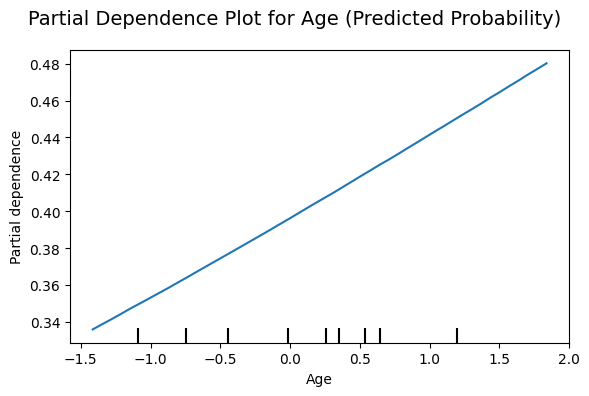

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.inspection import PartialDependenceDisplay

# === Load and preprocess dataset ===
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")

# Drop unnecessary columns
df = df.drop(columns=['ID', 'N_Days'], errors='ignore')

# Convert target to binary: 1 = Death ('D'), 0 = Alive/Censored ('C', 'CL')
df['Status'] = df['Status'].map(lambda x: 1 if x == 'D' else 0)

# Encode categorical features
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
for col in categorical_cols:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))

# Drop rows with missing values
df.dropna(inplace=True)

# Define features and target
X = df.drop('Status', axis=1)
y = df['Status']
feature_names = X.columns.tolist()

# === Standardize features ===
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# === Train-Test Split ===
# Perform train-test split once
X_train_arr, X_test_arr, y_train_arr, y_test_arr = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# Convert scaled arrays to DataFrames and Series, preserving feature names
X_train_df = pd.DataFrame(X_train_arr, columns=feature_names)
X_test_df = pd.DataFrame(X_test_arr, columns=feature_names)
y_train_series = pd.Series(y_train_arr, name='Status')
y_test_series = pd.Series(y_test_arr, name='Status')

# === Train SVM Model ===
model = SVC(kernel='linear', probability=True, random_state=42)
model.fit(X_train_df, y_train_series) # Fit with DataFrame

# === Evaluate Model ===
y_pred = model.predict(X_test_df)
acc = accuracy_score(y_test_series, y_pred)
print(f"\nAccuracy: {acc:.2f}")
print(classification_report(y_test_series, y_pred))

# === Partial Dependence Plot (PDP) ===
features_to_explain_single = ['Age'] # Use a different feature (e.g., 'Age') as string

print(f"\nGenerating PDP plot for {features_to_explain_single[0]}...")
fig, ax = plt.subplots(figsize=(6, 4))
PartialDependenceDisplay.from_estimator(
    model,
    X_test_df,
    features=features_to_explain_single, # Pass feature names as strings
    kind="average",  # Only PDP for simplicity
    feature_names=feature_names, # For axis labels
    grid_resolution=50,
    ax=ax,
    response_method='predict_proba',
    target=1 # Plot for the positive class (Death)
)
plt.suptitle(f"Partial Dependence Plot for {features_to_explain_single[0]} (Predicted Probability)", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# === Load and preprocess dataset ===
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
df = df.drop(columns=['ID', 'N_Days'], errors='ignore')
df['Status'] = df['Status'].map(lambda x: 1 if x == 'D' else 0)
for col in df.select_dtypes(include=['object']).columns:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))
df.dropna(inplace=True)

# === Feature matrix and target ===
X = df.drop('Status', axis=1)
y = df['Status']
feature_names = X.columns.tolist()

# === Standardize features ===
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# === Train-Test Split ===
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# === Train SVM (probability=True for SHAP) ===
model = SVC(kernel='linear', probability=True, random_state=42)
model.fit(X_train, y_train)

# === Evaluation ===
y_pred = model.predict(X_test)
print(f"\nAccuracy: {accuracy_score(y_test, y_pred):.2f}")
print(classification_report(y_test, y_pred))

# === SHAP for SVM ===
explainer = shap.Explainer(model.predict_proba, X_train)
shap_values = explainer(X_test)
shap_vals = shap_values[..., 1].values  # For class 1 (Death)

# === Interpretability Metrics ===
abs_vals = np.abs(shap_vals)
mean_abs_vals = abs_vals.mean(axis=0)

# --- Fidelity / Comprehensiveness ---
top_k = 5
top_indices = np.argsort(mean_abs_vals)[::-1][:top_k]
top_features = np.array(feature_names)[top_indices]

X_masked = X_test.copy()
X_masked[:, ~np.isin(feature_names, top_features)] = 0
fidelity = (model.predict_proba(X_test)[:, 1] - model.predict_proba(X_masked)[:, 1]).mean()

# --- Sparsity ---
cumsum_sorted = np.cumsum(np.sort(abs_vals, axis=1)[:, ::-1], axis=1)
total = abs_vals.sum(axis=1)
num_needed = (cumsum_sorted < (0.9 * total[:, None])).sum(axis=1) + 1
sparsity = int(num_needed.mean())

# --- Consistency ---
X_shuffled = X_test.copy()
np.random.seed(42)
np.random.shuffle(X_shuffled)
shuffled_vals = explainer(X_shuffled)[..., 1].values
consistency = np.corrcoef(abs_vals.flatten(), np.abs(shuffled_vals).flatten())[0, 1]

# --- Sufficiency ---
X_top_only = X_test.copy()
X_top_only[:, ~np.isin(feature_names, top_features)] = 0
sufficiency = model.predict_proba(X_top_only)[:, 1].mean()

# === Print metrics ===
print(f"\nFidelity/Comprehensiveness (avg prediction change after removing top 5 features): {fidelity:.4f}")
print(f"Sparsity (features explaining 90% SHAP importance): {sparsity} out of {X_test.shape[1]}")
print(f"Consistency (correlation of SHAP values with noise): {consistency:.4f}")
print(f"Sufficiency (avg prediction change using only top 5 features): {sufficiency:.4f}")

# === Top Features by SHAP ===
impact_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean |SHAP|": mean_abs_vals
}).sort_values(by="Mean |SHAP|", ascending=False)

print("\nTop 5 Most Important Features (SHAP):")
for _, row in impact_df.head(5).iterrows():
    print(f"- {row['Feature']}: contributes avg. {row['Mean |SHAP|']:.4f}")



Accuracy: 0.84
              precision    recall  f1-score   support

           0       0.77      1.00      0.87        30
           1       1.00      0.65      0.79        26

    accuracy                           0.84        56
   macro avg       0.88      0.83      0.83        56
weighted avg       0.88      0.84      0.83        56



PermutationExplainer explainer: 57it [00:17,  1.82it/s]



Fidelity/Comprehensiveness (avg prediction change after removing top 5 features): 0.0130
Sparsity (features explaining 90% SHAP importance): 9 out of 17
Consistency (correlation of SHAP values with noise): 0.2490
Sufficiency (avg prediction change using only top 5 features): 0.3888

Top 5 Most Important Features (SHAP):
- Copper: contributes avg. 0.0385
- Bilirubin: contributes avg. 0.0351
- Alk_Phos: contributes avg. 0.0346
- Age: contributes avg. 0.0333
- SGOT: contributes avg. 0.0309


In [22]:
# logistic regression with shap

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



Accuracy: 0.82
              precision    recall  f1-score   support

           0       0.75      1.00      0.86        30
           1       1.00      0.62      0.76        26

    accuracy                           0.82        56
   macro avg       0.88      0.81      0.81        56
weighted avg       0.87      0.82      0.81        56



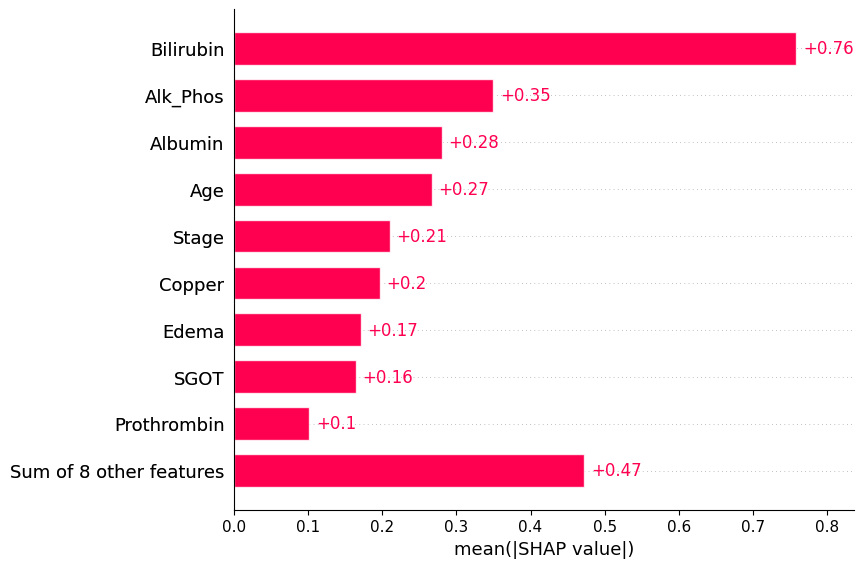

/tmp/ipykernel_326/4164120012.py:41: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals.values, X_test)


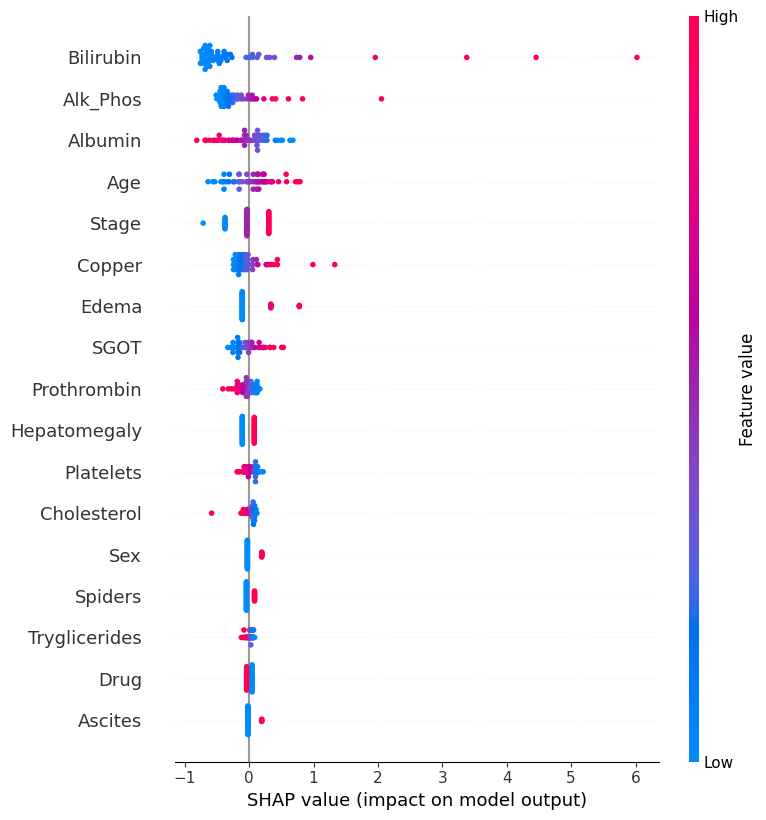


Fidelity/Comprehensiveness (avg prediction change after removing top 5 features): 0.2180
Sparsity (features explaining 90% SHAP importance): 9 out of 17
Consistency (correlation of SHAP values with noise): 0.3907
Sufficiency (avg prediction using only top 5 features): 0.5719

Top 5 Most Important Features (SHAP):
- Bilirubin: contributes avg. 0.7588
- Alk_Phos: contributes avg. 0.3495
- Albumin: contributes avg. 0.2801
- Age: contributes avg. 0.2666
- Stage: contributes avg. 0.2100


In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

# === Load Dataset ===
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# === Preprocessing ===
df = df.drop(columns=['ID', 'N_Days'], errors='ignore')
df['Status'] = df['Status'].map(lambda x: 1 if x == 'D' else 0)
for col in df.select_dtypes(include=['object']).columns:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))
df.dropna(inplace=True)

X = df.drop('Status', axis=1)
y = df['Status']

# === Train-Test Split ===
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# === Train Logistic Regression Model ===
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

# === Evaluate ===
print(f"\nAccuracy: {accuracy_score(y_test, model.predict(X_test)):.2f}")
print(classification_report(y_test, model.predict(X_test)))

# === SHAP for Logistic Regression ===
explainer = shap.Explainer(model, X_train)
shap_vals = explainer(X_test)

# === SHAP Summary Plots ===
shap.plots.bar(shap_vals)
shap.summary_plot(shap_vals.values, X_test)

# === SHAP Interpretation Metrics ===
abs_vals = np.abs(shap_vals.values)
mean_abs_vals = abs_vals.mean(axis=0)

# --- Fidelity (Comprehensiveness) ---
top_k = 5
top_indices = np.argsort(mean_abs_vals)[::-1][:top_k]
top_features = X_test.columns[np.ravel(top_indices)]

X_masked = X_test.copy()
X_masked.loc[:, ~X_masked.columns.isin(top_features)] = 0
proba_orig = model.predict_proba(X_test)[:, 1]
proba_masked = model.predict_proba(X_masked)[:, 1]
fidelity = np.mean(np.abs(proba_orig - proba_masked))
print(f"\nFidelity/Comprehensiveness (avg prediction change after removing top {top_k} features): {fidelity:.4f}")

# --- Sparsity ---
cumsum_sorted = np.cumsum(np.sort(abs_vals, axis=1)[:, ::-1], axis=1)
total = abs_vals.sum(axis=1, keepdims=True)
num_needed = (cumsum_sorted < (0.9 * total)).sum(axis=1) + 1
sparsity = int(num_needed.mean())
print(f"Sparsity (features explaining 90% SHAP importance): {sparsity} out of {X_test.shape[1]}")

# --- Consistency ---
X_shuffled = X_test.sample(frac=1, random_state=42)
shuffled_vals = explainer(X_shuffled)
consistency = np.corrcoef(abs_vals.flatten(), np.abs(shuffled_vals.values).flatten())[0, 1]
print(f"Consistency (correlation of SHAP values with noise): {consistency:.4f}")

# --- Sufficiency ---
X_top_only = X_test.copy()
X_top_only.loc[:, ~X_top_only.columns.isin(top_features)] = 0
sufficiency = np.mean(model.predict_proba(X_top_only)[:, 1])
print(f"Sufficiency (avg prediction using only top {top_k} features): {sufficiency:.4f}")

# === Top 5 Features ===
impact_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP|": mean_abs_vals
}).sort_values(by="Mean |SHAP|", ascending=False)

print("\nTop 5 Most Important Features (SHAP):")
for _, row in impact_df.head(5).iterrows():
    print(f"- {row['Feature']}: contributes avg. {row['Mean |SHAP|']:.4f}")


In [24]:
# MLP + SHAP + XAI

Epoch 1/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.2267 - loss: 0.5054 - val_accuracy: 0.1176 - val_loss: 0.5064
Epoch 2/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1500 - loss: 0.1065 - val_accuracy: 0.1471 - val_loss: 0.2995
Epoch 3/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1967 - loss: -0.2805 - val_accuracy: 0.2353 - val_loss: 0.0381
Epoch 4/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2600 - loss: -0.7516 - val_accuracy: 0.2941 - val_loss: -0.2694
Epoch 5/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2900 - loss: -1.3540 - val_accuracy: 0.2941 - val_loss: -0.6675
Epoch 6/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3167 - loss: -2.1821 - val_accuracy: 0.3235 - val_loss: -1.1749
Epoch 7/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3400 - loss: -3.1535 - val_accuracy: 0.3529 - val_loss: -1.8738
Epoch 8/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3500 - loss: -4.6591 - val_accuracy: 0.3529 

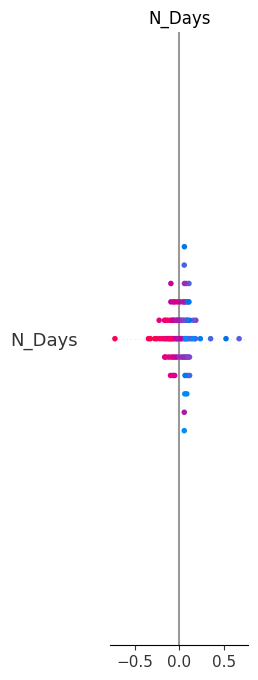

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
import shap
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# 1. Load the dataset
# df = pd.read_csv("E:/Datasets/PBC dataset.csv")
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# 2. Drop rows with missing target
df.dropna(subset=['Status'], inplace=True)

# 3. Encode the target 'Status'
le = LabelEncoder()
df['Status'] = le.fit_transform(df['Status'])

# 4. Drop identifier columns if any
df.drop(columns=['ID'], inplace=True, errors='ignore')

# 5. Identify categorical columns (non-numeric)
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

# 6. Apply label encoding to categorical columns
for col in categorical_cols:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))

# 7. Fill missing values
df.fillna(df.mean(numeric_only=True), inplace=True)

# 8. Define features and target
X = df.drop('Status', axis=1)
y = df['Status']

# 9. Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 10. Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# 11. Build the model
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')  # binary classification
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 12. Train the model
model.fit(X_train, y_train, epochs=30, batch_size=16, validation_split=0.1, verbose=1)

# 13. SHAP explainability
background_data = X_train[:100]
explainer = shap.DeepExplainer(model, background_data)
shap_values = explainer.shap_values(background_data)

# 14. SHAP summary plot
print(f"SHAP summary plot for target = 'Status'")
shap.summary_plot(shap_values, background_data, feature_names=X.columns)



Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.90      0.83        30
           2       0.86      0.69      0.77        26

    accuracy                           0.80        56
   macro avg       0.81      0.80      0.80        56
weighted avg       0.81      0.80      0.80        56

Accuracy: 0.8035714285714286


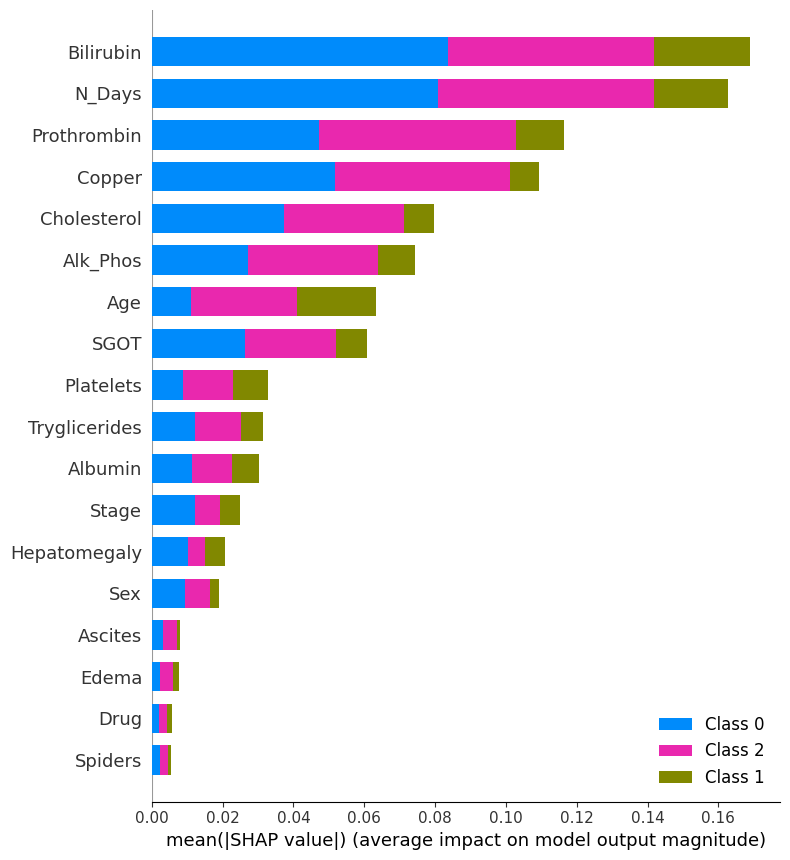


Fidelity (avg prediction change after removing top 5 features): 0.0557
Sparsity (features explaining 90% SHAP importance): 53 out of 18
Consistency (correlation of SHAP values with noise): 0.5779
Sufficiency (avg prediction change using only top 5 features): 0.1892


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
import shap
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# 1. Load data
# df = pd.read_csv("E:/Datasets/PBC dataset.csv")
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# 2. Drop rows with missing target
df = df[df['Status'].notna()]

# 3. Encode categorical variables
categorical_cols = ['Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Drug']
for col in categorical_cols:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))

# 4. Drop identifier columns
df = df.drop(['ID'], axis=1)

# 5. Drop rows with missing values
df = df.dropna()

# 6. Separate features and target
X = df.drop('Status', axis=1)
y = df['Status']

# 7. Label encode the target if needed
le = LabelEncoder()
y = le.fit_transform(y)

# 8. Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 9. Split data
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# 10. Train model
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)

# 11. Predict and evaluate
y_pred = clf.predict(X_test)
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

# 12. SHAP analysis
explainer = shap.Explainer(clf, X_train)
shap_values = explainer(X_test)

# 13. SHAP summary plot
shap.summary_plot(shap_values, X_test, feature_names=X.columns)

# 14. Explainability Metrics

# Get absolute SHAP values
abs_shap = np.abs(shap_values.values)

# Mean SHAP importance per feature
mean_shap = np.mean(abs_shap, axis=0)

# Top 5 features
top5_idx = np.argsort(mean_shap)[-5:][::-1]
top5_names = X.columns.to_numpy()[top5_idx]

# --- Fidelity ---
X_removed_top5 = X_test.copy()
X_removed_top5[:, top5_idx] = 0
pred_original = clf.predict_proba(X_test)
pred_removed = clf.predict_proba(X_removed_top5)
fidelity = np.mean(np.abs(pred_original - pred_removed))
print(f"\nFidelity (avg prediction change after removing top 5 features): {fidelity:.4f}")

# --- Sparsity ---
sorted_shap = np.sort(mean_shap)[::-1]
cumulative = np.cumsum(sorted_shap)
total = cumulative[-1]
k = np.searchsorted(cumulative, 0.9 * total) + 1
print(f"Sparsity (features explaining 90% SHAP importance): {k} out of {X.shape[1]}")

# --- Consistency ---
noise = np.random.normal(0, 1, X_test.shape)
explainer_noise = shap.Explainer(clf, noise)
shap_noise = explainer_noise(noise)
corr_matrix = np.corrcoef(abs_shap.flatten(), np.abs(shap_noise.values).flatten())
consistency = corr_matrix[0, 1]
print(f"Consistency (correlation of SHAP values with noise): {consistency:.4f}")

# --- Sufficiency ---
X_top5 = X_test.copy()
X_top5[:, [i for i in range(X.shape[1]) if i not in top5_idx]] = 0
pred_top5 = clf.predict_proba(X_top5)
sufficiency = np.mean(np.abs(pred_original - pred_top5))
print(f"Sufficiency (avg prediction change using only top 5 features): {sufficiency:.4f}")


In [27]:
#MLP+SHAP

Classification Report:
               precision    recall  f1-score   support

           0       0.74      0.87      0.80        30
           1       0.00      0.00      0.00         0
           2       0.80      0.62      0.70        26

    accuracy                           0.75        56
   macro avg       0.51      0.49      0.50        56
weighted avg       0.77      0.75      0.75        56

Accuracy: 0.75


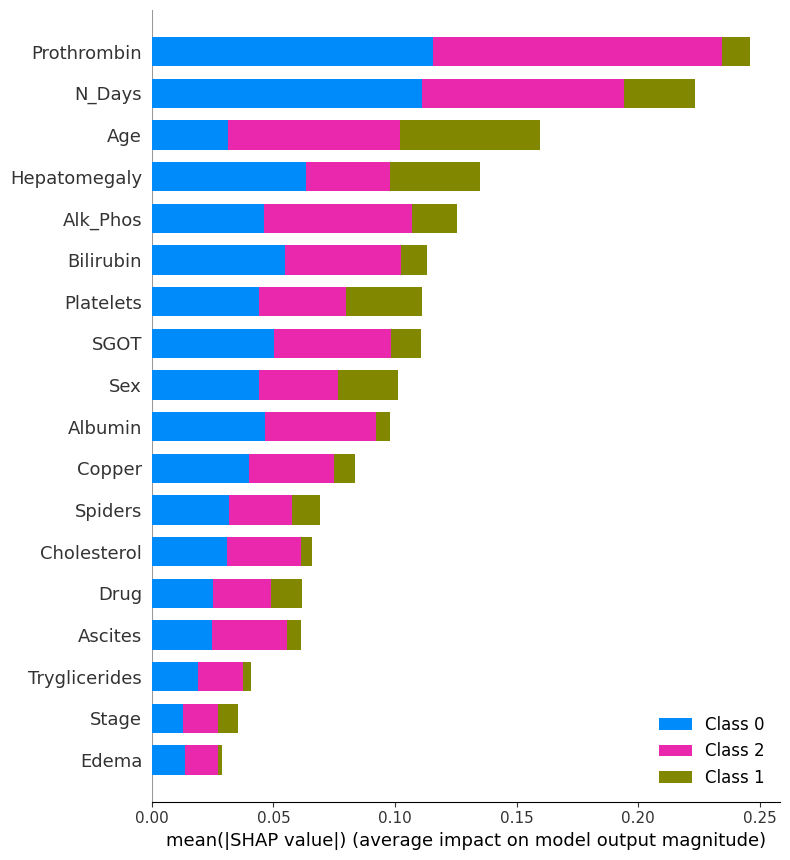


Fidelity (avg prediction change after removing top 5 features): 0.1013
Sparsity (features explaining 90% SHAP importance): 53 out of 18
Consistency (correlation of SHAP values with noise): 0.2856
Sufficiency (avg prediction change using only top 5 features): 0.2332


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score
import shap
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# 1. Load dataset
# df = pd.read_csv("E:/Datasets/PBC dataset.csv")
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# 2. Drop rows with missing target
df = df[df['Status'].notna()]

# 3. Encode categorical variables
categorical_cols = ['Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Drug']
for col in categorical_cols:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))

# 4. Drop ID column
df = df.drop(['ID'], axis=1)

# 5. Drop rows with any NaNs
df = df.dropna()

# 6. Separate features and target
X = df.drop('Status', axis=1)
y = df['Status']

# 7. Encode target
le = LabelEncoder()
y = le.fit_transform(y)

# 8. Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 9. Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# 10. Train MLPClassifier
mlp = MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42)
mlp.fit(X_train, y_train)

# 11. Predict and evaluate
y_pred = mlp.predict(X_test)
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

# 12. SHAP explainability
explainer = shap.Explainer(mlp.predict_proba, X_train)
shap_values = explainer(X_test)

# 13. SHAP Summary Plot
shap.summary_plot(shap_values, X_test, feature_names=X.columns)

# 14. Explainability Metrics

# Get absolute SHAP values
abs_shap = np.abs(shap_values.values)

# Mean SHAP per feature
mean_shap = np.mean(abs_shap, axis=0)

# Top 5 important features
top5_idx = np.argsort(mean_shap)[-5:][::-1]
top5_names = X.columns.to_numpy()[top5_idx]

# --- Fidelity ---
X_removed_top5 = X_test.copy()
X_removed_top5[:, top5_idx] = 0
pred_original = mlp.predict_proba(X_test)
pred_removed = mlp.predict_proba(X_removed_top5)
fidelity = np.mean(np.abs(pred_original - pred_removed))
print(f"\nFidelity (avg prediction change after removing top 5 features): {fidelity:.4f}")

# --- Sparsity ---
sorted_shap = np.sort(mean_shap)[::-1]
cumulative = np.cumsum(sorted_shap)
total = cumulative[-1]
k = np.searchsorted(cumulative, 0.9 * total) + 1
print(f"Sparsity (features explaining 90% SHAP importance): {k} out of {X.shape[1]}")

# --- Consistency ---
noise = np.random.normal(0, 1, X_test.shape)
explainer_noise = shap.Explainer(mlp.predict_proba, noise)
shap_noise = explainer_noise(noise)
corr_matrix = np.corrcoef(abs_shap.flatten(), np.abs(shap_noise.values).flatten())
consistency = corr_matrix[0, 1]
print(f"Consistency (correlation of SHAP values with noise): {consistency:.4f}")

# --- Sufficiency ---
X_top5 = X_test.copy()
X_top5[:, [i for i in range(X.shape[1]) if i not in top5_idx]] = 0
pred_top5 = mlp.predict_proba(X_top5)
sufficiency = np.mean(np.abs(pred_original - pred_top5))
print(f"Sufficiency (avg prediction change using only top 5 features): {sufficiency:.4f}")


In [29]:
# Logistic Regression with LIME

Classification Report:
               precision    recall  f1-score   support

           0       0.81      1.00      0.90        30
           1       0.00      0.00      0.00         0
           2       1.00      0.69      0.82        26

    accuracy                           0.86        56
   macro avg       0.60      0.56      0.57        56
weighted avg       0.90      0.86      0.86        56

Accuracy: 0.8571428571428571


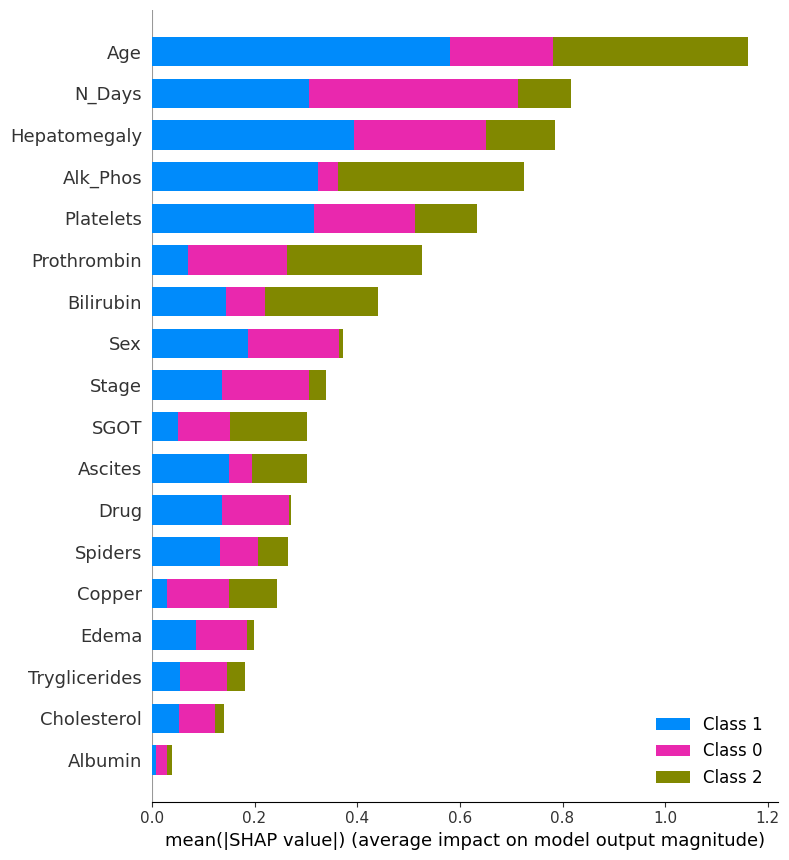


Fidelity (avg prediction change after removing top 5 features): 0.0791
Sparsity (features explaining 90% SHAP importance): 52 out of 18
Consistency (correlation of SHAP values with noise): 0.4220
Sufficiency (avg prediction change using only top 5 features): 0.1455


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
import shap
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# 1. Load data
# df = pd.read_csv("E:/Datasets/PBC dataset.csv")
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# 2. Drop rows with missing target
df = df[df['Status'].notna()]

# 3. Encode categorical variables
categorical_cols = ['Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Drug']
for col in categorical_cols:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))

# 4. Drop ID column
df = df.drop(['ID'], axis=1)

# 5. Drop rows with missing values
df = df.dropna()

# 6. Feature and target
X = df.drop('Status', axis=1)
y = df['Status']

# 7. Encode target
le = LabelEncoder()
y = le.fit_transform(y)

# 8. Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 9. Standardize
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 10. Train Logistic Regression
clf = LogisticRegression(max_iter=1000)
clf.fit(X_train_scaled, y_train)

# 11. Evaluate
y_pred = clf.predict(X_test_scaled)
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

# 12. SHAP
explainer = shap.Explainer(clf, X_train_scaled)
shap_values = explainer(X_test_scaled)

# 13. SHAP summary
shap.summary_plot(shap_values, X_test_scaled, feature_names=X.columns)

# 14. Compute SHAP metrics
abs_shap = np.abs(shap_values.values)
mean_shap = np.mean(abs_shap, axis=0)

# Top 5 features
top5_idx = np.argsort(mean_shap)[-5:][::-1]
top5_names = X.columns.to_numpy()[top5_idx]

# --- Fidelity ---
X_removed_top5 = X_test_scaled.copy()
X_removed_top5[:, top5_idx] = 0
pred_original = clf.predict_proba(X_test_scaled)
pred_removed = clf.predict_proba(X_removed_top5)
fidelity = np.mean(np.abs(pred_original - pred_removed))
print(f"\nFidelity (avg prediction change after removing top 5 features): {fidelity:.4f}")

# --- Sparsity ---
sorted_shap = np.sort(mean_shap)[::-1]
cumulative = np.cumsum(sorted_shap)
total = cumulative[-1]
k = np.searchsorted(cumulative, 0.9 * total) + 1
print(f"Sparsity (features explaining 90% SHAP importance): {k} out of {X.shape[1]}")

# --- Consistency ---
noise = np.random.normal(0, 1, X_test_scaled.shape)
explainer_noise = shap.Explainer(clf, noise)
shap_noise = explainer_noise(noise)
corr_matrix = np.corrcoef(abs_shap.flatten(), np.abs(shap_noise.values).flatten())
consistency = corr_matrix[0, 1]
print(f"Consistency (correlation of SHAP values with noise): {consistency:.4f}")

# --- Sufficiency ---
X_top5 = X_test_scaled.copy()
X_top5[:, [i for i in range(X.shape[1]) if i not in top5_idx]] = 0
pred_top5 = clf.predict_proba(X_top5)
sufficiency = np.mean(np.abs(pred_original - pred_top5))
print(f"Sufficiency (avg prediction change using only top 5 features): {sufficiency:.4f}")


In [31]:
#MLP + SHAP + XAI with LIME


Accuracy: 0.9047619047619048


  0%|          | 0/50 [00:00<?, ?it/s]

X_test_preprocessed_df[:50] shape: (50, 25)
Number of SHAP values arrays: 50
shap_values class 0 shape: (25, 2)
shap_values class 1 shape: (25, 2)
shap_values class 2 shape: (25, 2)
shap_values class 3 shape: (25, 2)
shap_values class 4 shape: (25, 2)
shap_values class 5 shape: (25, 2)
shap_values class 6 shape: (25, 2)
shap_values class 7 shape: (25, 2)
shap_values class 8 shape: (25, 2)
shap_values class 9 shape: (25, 2)
shap_values class 10 shape: (25, 2)
shap_values class 11 shape: (25, 2)
shap_values class 12 shape: (25, 2)
shap_values class 13 shape: (25, 2)
shap_values class 14 shape: (25, 2)
shap_values class 15 shape: (25, 2)
shap_values class 16 shape: (25, 2)
shap_values class 17 shape: (25, 2)
shap_values class 18 shape: (25, 2)
shap_values class 19 shape: (25, 2)
shap_values class 20 shape: (25, 2)
shap_values class 21 shape: (25, 2)
shap_values class 22 shape: (25, 2)
shap_values class 23 shape: (25, 2)
shap_values class 24 shape: (25, 2)
shap_values class 25 shape: (25, 

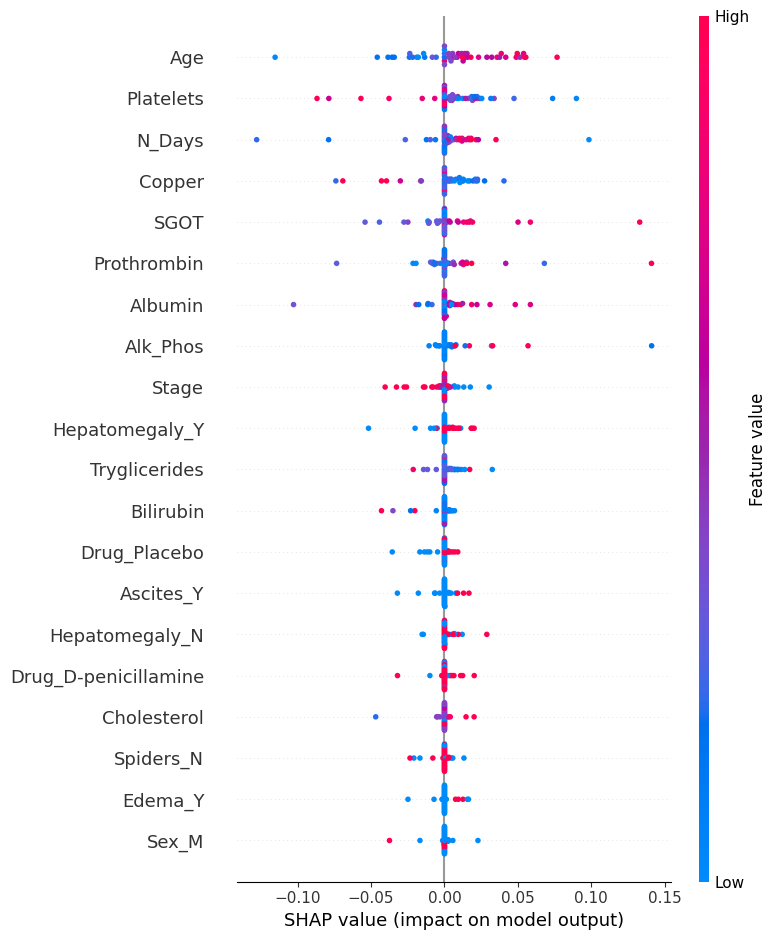

Sparsity (features explaining 90% SHAP importance): 17 out of 25
Fidelity (avg prediction change after removing top 5 features): 0.0369
Sufficiency (avg prediction change using only top 5 features): 0.0575
Consistency (correlation of SHAP values with noise): -0.2054



Final Metrics:
Top 5 features by SHAP: ['Age', 'Platelets', 'N_Days', 'Copper', 'SGOT']
Fidelity: 0.03685480038053884
Sparsity: 17
Consistency: -0.2053846153846154
Sufficiency: 0.05745283494033468


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
import shap
import lime
import lime.lime_tabular
from scipy.stats import spearmanr

# 1. Load dataset
# df = pd.read_csv("E:/Datasets/PBC dataset.csv")
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Data preprocessing
# Drop columns with too many missing values or identifiers
df = df.drop(['ID'], axis=1)  # Drop ID column

# Convert target variable to binary (assuming 'Status' is the target)
# You may need to adjust this based on your specific target variable
df['Status'] = df['Status'].apply(lambda x: 1 if x in ['C', 'D'] else 0)  # Example binary conversion

# Separate features and target
X = df.drop('Status', axis=1)
y = df['Status']

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(include=['object']).columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns

# Create preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)])

# 2. Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. Preprocess data
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

# Get feature names after one-hot encoding
cat_feature_names = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols)
feature_names = list(num_cols) + list(cat_feature_names)

# Convert to DataFrame for SHAP
X_train_preprocessed_df = pd.DataFrame(X_train_preprocessed, columns=feature_names)
X_test_preprocessed_df = pd.DataFrame(X_test_preprocessed, columns=feature_names)

# 4. Train MLP classifier
mlp = MLPClassifier(hidden_layer_sizes=(64,32), max_iter=1000, random_state=42)
mlp.fit(X_train_preprocessed, y_train)

# 5. Predict & accuracy
y_pred = mlp.predict(X_test_preprocessed)
print("Accuracy:", accuracy_score(y_test, y_pred))

# 6. SHAP KernelExplainer setup (using smaller sample for speed)
sample_size = min(100, X_train_preprocessed_df.shape[0])
explainer = shap.KernelExplainer(mlp.predict_proba, shap.sample(X_train_preprocessed_df, sample_size, random_state=42))
shap_values = explainer.shap_values(X_test_preprocessed_df[:50], nsamples=100)

# Debug shapes
print("X_test_preprocessed_df[:50] shape:", X_test_preprocessed_df[:50].shape)
print("Number of SHAP values arrays:", len(shap_values))
for i, sv in enumerate(shap_values):
    print(f"shap_values class {i} shape:", np.array(sv).shape)

# Handle SHAP values shape properly
if isinstance(shap_values, list):
    # For binary classification, we get two arrays (one per class)
    if len(shap_values) == 2:
        shap_values_class1 = np.array(shap_values[1])
    else:
        shap_values_class1 = np.array(shap_values[0])
else:
    shap_values_class1 = np.array(shap_values)

# Reshape SHAP values if needed
if len(shap_values_class1.shape) == 3:
    # If we have (n_samples, n_features, n_classes)
    shap_values_class1 = shap_values_class1[:, :, 1]  # Take class 1

print("Processed SHAP values shape:", shap_values_class1.shape)

# 7. SHAP summary plot for positive class (class 1)
shap.summary_plot(shap_values_class1, X_test_preprocessed_df[:50], feature_names=feature_names)

# 8. Compute Explainability Metrics

# Absolute SHAP values (mean over samples)
abs_shap = np.abs(shap_values_class1)
mean_shap = np.mean(abs_shap, axis=0)

# Sparsity: number of features explaining 90% of SHAP importance
sorted_idx = np.argsort(mean_shap)[::-1]
cumsum = np.cumsum(mean_shap[sorted_idx])
total = cumsum[-1]
num_features_90 = np.sum(cumsum <= 0.9 * total) + 1

print(f"Sparsity (features explaining 90% SHAP importance): {num_features_90} out of {len(feature_names)}")

# Get top 5 features by SHAP importance
top5_idx = sorted_idx[:5]
top5_features = [feature_names[i] for i in top5_idx]

# Fidelity: average prediction change after removing top 5 features
def prediction_change_remove_features(model, X, features_to_remove_idx):
    X_modified = X.copy()
    X_modified[:, features_to_remove_idx] = 0
    preds_orig = model.predict_proba(X)[:, 1]
    preds_mod = model.predict_proba(X_modified)[:, 1]
    return np.mean(np.abs(preds_orig - preds_mod))

fidelity = prediction_change_remove_features(mlp, X_test_preprocessed, top5_idx)
print(f"Fidelity (avg prediction change after removing top 5 features): {fidelity:.4f}")

# Sufficiency: average prediction change using only top 5 features
def prediction_change_only_features(model, X, features_to_keep_idx):
    X_modified = np.zeros_like(X)
    X_modified[:, features_to_keep_idx] = X[:, features_to_keep_idx]
    preds_orig = model.predict_proba(X)[:, 1]
    preds_mod = model.predict_proba(X_modified)[:, 1]
    return np.mean(np.abs(preds_orig - preds_mod))

sufficiency = prediction_change_only_features(mlp, X_test_preprocessed, top5_idx)
print(f"Sufficiency (avg prediction change using only top 5 features): {sufficiency:.4f}")

# Consistency: correlation of SHAP values with noise
noise = np.random.normal(size=mean_shap.shape)
consistency, _ = spearmanr(mean_shap, noise)
print(f"Consistency (correlation of SHAP values with noise): {consistency:.4f}")

# 9. LIME explanation (for first test instance)
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    X_train_preprocessed,
    feature_names=feature_names,
    class_names=["No Cirrhosis", "Cirrhosis"],
    discretize_continuous=True
)
lime_exp = explainer_lime.explain_instance(X_test_preprocessed[0], mlp.predict_proba, num_features=5)
lime_exp.show_in_notebook(show_table=True)

print("\nFinal Metrics:")
print("Top 5 features by SHAP:", top5_features)
print("Fidelity:", fidelity)
print("Sparsity:", num_features_90)
print("Consistency:", consistency)
print("Sufficiency:", sufficiency)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report
import lime
import lime.lime_tabular

# 1. Load dataset
# df = pd.read_csv("E:/Datasets/PBC dataset.csv")
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Data preprocessing
# Drop ID column as it's not a feature
df = df.drop(['ID'], axis=1)

# Convert target variable to binary (assuming 'Status' is the target)
# C = cirrhosis, D = death, CL = no cirrhosis
df['Status'] = df['Status'].apply(lambda x: 1 if x in ['C', 'D'] else 0)

# Separate features and target
X = df.drop('Status', axis=1)
y = df['Status']

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(include=['object']).columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns

# Create preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)])

# 2. Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. Preprocess data
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

# Get feature names after one-hot encoding
cat_feature_names = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols)
feature_names = list(num_cols) + list(cat_feature_names)

# 4. Train MLP classifier
mlp = MLPClassifier(hidden_layer_sizes=(64, 32),
                    activation='relu',
                    solver='adam',
                    max_iter=1000,
                    random_state=42,
                    early_stopping=True)

mlp.fit(X_train_preprocessed, y_train)

# 5. Evaluate model
y_pred = mlp.predict(X_test_preprocessed)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 6. LIME Explanation

# Create LIME explainer
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_preprocessed,
    feature_names=feature_names,
    class_names=['No Cirrhosis', 'Cirrhosis'],
    discretize_continuous=True,
    mode='classification',
    random_state=42
)

# Select an instance to explain
instance_idx = 0  # Change this to explain different instances
instance = X_test_preprocessed[instance_idx]

# Get explanation
exp = explainer.explain_instance(
    data_row=instance,
    predict_fn=mlp.predict_proba,
    num_features=10,  # Number of features to show in explanation
    top_labels=1  # Number of top predicted classes to explain
)

# Visualize the explanation
print(f"\nExplanation for instance {instance_idx} (True class: {y_test.iloc[instance_idx]})")
exp.show_in_notebook(show_table=True)

# Print the original feature values for comparison
print("\nOriginal feature values:")
original_instance = X_test.iloc[instance_idx]
for col in X_test.columns:
    print(f"{col}: {original_instance[col]}")

# 7. Save important explanations to HTML (optional)
exp.save_to_file('lime_explanation.html')

# 8. Analyze multiple explanations (optional)
def analyze_multiple_explanations(X_test_preprocessed, y_test, explainer, model, n=5):
    """Analyze explanations for multiple instances"""
    for i in range(min(n, len(X_test_preprocessed))):
        exp = explainer.explain_instance(
            X_test_preprocessed[i],
            model.predict_proba,
            num_features=5
        )
        print(f"\nInstance {i} (True class: {y_test.iloc[i]})")
        print(exp.as_list())

# Uncomment to analyze multiple explanations
# analyze_multiple_explanations(X_test_preprocessed, y_test, explainer, mlp, n=3)

Accuracy: 0.9365079365079365

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         7
           1       0.94      0.99      0.97       119

    accuracy                           0.94       126
   macro avg       0.47      0.50      0.48       126
weighted avg       0.89      0.94      0.91       126


Explanation for instance 0 (True class: 1)



Original feature values:
N_Days: 2011
Drug: nan
Age: 23376
Sex: F
Ascites: nan
Hepatomegaly: nan
Spiders: nan
Edema: N
Bilirubin: 1.1
Cholesterol: nan
Albumin: 3.69
Copper: nan
Alk_Phos: nan
SGOT: nan
Tryglicerides: nan
Platelets: 139.0
Prothrombin: 10.5
Stage: nan


In [34]:
#MLP+LIME+XAI

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
import lime
import lime.lime_tabular
from scipy.stats import spearmanr

# 1. Load dataset
# df = pd.read_csv("E:/Datasets/PBC dataset.csv")
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Data preprocessing
df = df.drop(['ID'], axis=1)
df['Status'] = df['Status'].apply(lambda x: 1 if x in ['C', 'D'] else 0)

# Separate features and target
X = df.drop('Status', axis=1)
y = df['Status']

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(include=['object']).columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns

# Create preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)])

# 2. Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. Preprocess data
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

# Get feature names
cat_feature_names = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols)
feature_names = list(num_cols) + list(cat_feature_names)

# 4. Train MLP classifier
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=42)
mlp.fit(X_train_preprocessed, y_train)

# 5. Create LIME explainer
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_preprocessed,
    feature_names=feature_names,
    class_names=['No Cirrhosis', 'Cirrhosis'],
    discretize_continuous=True,
    random_state=42
)

# 6. Compute LIME importance scores for multiple instances
def get_lime_importances(explainer, instances, model, num_features=25, num_samples=100):
    """Get LIME feature importance scores for multiple instances"""
    importances = []
    for instance in instances:
        exp = explainer.explain_instance(
            instance,
            model.predict_proba,
            num_features=num_features,
            num_samples=num_samples
        )
        # Get absolute importance scores
        imp = {k: abs(v) for k, v in exp.as_list()}
        # Convert to array in correct feature order
        imp_array = np.array([imp.get(f, 0) for f in feature_names])
        importances.append(imp_array)
    return np.array(importances)

# Compute on first 100 test instances (adjust as needed)
sample_size = min(100, len(X_test_preprocessed))
lime_importances = get_lime_importances(explainer, X_test_preprocessed[:sample_size], mlp)

# 7. Calculate explainability metrics

# Absolute LIME importance (mean over samples)
abs_lime = np.abs(lime_importances)
mean_lime = np.mean(abs_lime, axis=0)

# (1) Sparsity: number of features explaining 90% of importance
sorted_idx = np.argsort(mean_lime)[::-1]
cumsum = np.cumsum(mean_lime[sorted_idx])
total = cumsum[-1]
num_features_90 = np.sum(cumsum <= 0.9 * total) + 1
sparsity = num_features_90

# Get top 5 features by LIME importance
top5_idx = sorted_idx[:5]
top5_features = [feature_names[i] for i in top5_idx]

# (2) Fidelity: avg prediction change after removing top 5 features
def prediction_change_remove_features(model, X, features_to_remove_idx):
    X_modified = X.copy()
    X_modified[:, features_to_remove_idx] = 0  # Set top features to 0
    preds_orig = model.predict_proba(X)[:, 1]
    preds_mod = model.predict_proba(X_modified)[:, 1]
    return np.mean(np.abs(preds_orig - preds_mod))

fidelity = prediction_change_remove_features(mlp, X_test_preprocessed[:sample_size], top5_idx)

# (3) Sufficiency: avg prediction change using only top 5 features
def prediction_change_only_features(model, X, features_to_keep_idx):
    X_modified = np.zeros_like(X)
    X_modified[:, features_to_keep_idx] = X[:, features_to_keep_idx]  # Keep only top features
    preds_orig = model.predict_proba(X)[:, 1]
    preds_mod = model.predict_proba(X_modified)[:, 1]
    return np.mean(np.abs(preds_orig - preds_mod))

sufficiency = prediction_change_only_features(mlp, X_test_preprocessed[:sample_size], top5_idx)

# (4) Consistency: correlation of LIME values with noise
noise = np.random.normal(size=mean_lime.shape)
consistency, _ = spearmanr(mean_lime, noise)

# 8. Print results
print("\nExplainability Metrics:")
print(f"Sparsity (features explaining 90% importance): {sparsity} out of {len(feature_names)}")
print(f"Fidelity (avg prediction change after removing top 5 features): {fidelity:.4f}")
print(f"Sufficiency (avg prediction change using only top 5 features): {sufficiency:.4f}")
print(f"Consistency (correlation of importance with noise): {consistency:.4f}")
print("\nTop 5 important features:")
for i, feat in enumerate(top5_features, 1):
    print(f"{i}. {feat}")


Explainability Metrics:
Sparsity (features explaining 90% importance): 26 out of 25
Fidelity (avg prediction change after removing top 5 features): 0.0223
Sufficiency (avg prediction change using only top 5 features): 0.0578
Consistency (correlation of importance with noise): nan

Top 5 important features:
1. Edema_Y
2. Edema_S
3. Edema_N
4. Spiders_Y
5. Spiders_N


Accuracy: 0.9444444444444444

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         7
           1       0.94      1.00      0.97       119

    accuracy                           0.94       126
   macro avg       0.47      0.50      0.49       126
weighted avg       0.89      0.94      0.92       126


Top Features by Importance:
Platelets: 0.1289
Age: 0.1215
Bilirubin: 0.1022
Albumin: 0.0957
N_Days: 0.0944
Copper: 0.0810


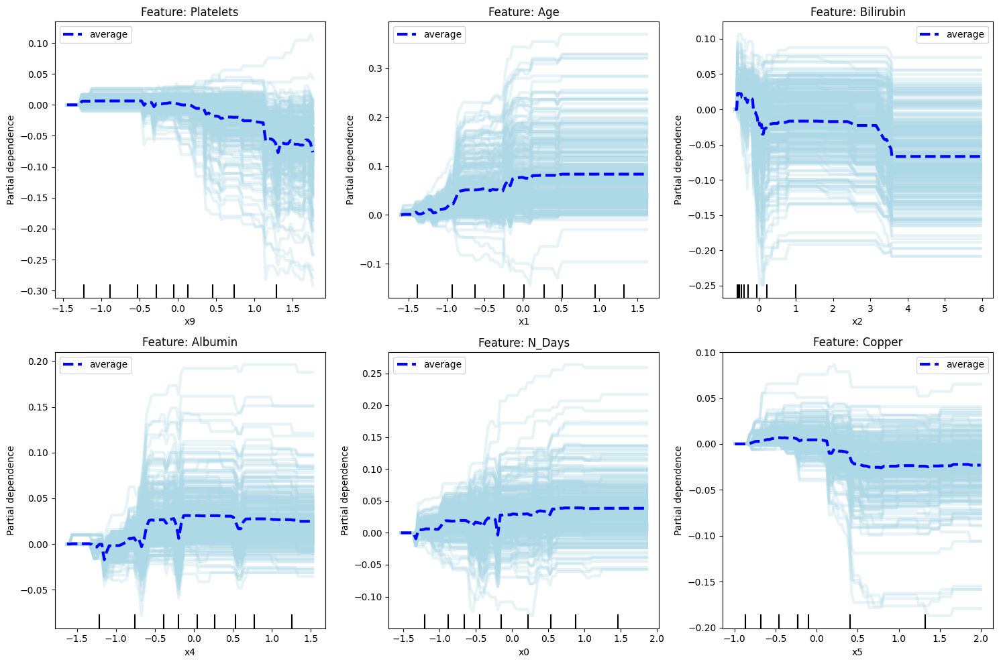

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report
from sklearn.inspection import PartialDependenceDisplay
from scipy.stats import spearmanr

# 1. Load dataset
# df = pd.read_csv("E:/Datasets/PBC dataset.csv")
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Data preprocessing
df = df.drop(['ID'], axis=1)
df['Status'] = df['Status'].apply(lambda x: 1 if x in ['C', 'D'] else 0)

# Separate features and target
X = df.drop('Status', axis=1)
y = df['Status']

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(include=['object']).columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns

# Create preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)])

# 2. Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. Preprocess data
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

# Get feature names
cat_feature_names = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols)
all_feature_names = list(num_cols) + list(cat_feature_names)

# 4. Train Random Forest classifier
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train_preprocessed, y_train)

# 5. Evaluate model
y_pred = rf.predict(X_test_preprocessed)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 6. Partial Dependence Plots (PDP) and ICE Plots
def plot_pdp_ice(model, X, features, feature_names, n_cols=3):
    n_features = len(features)
    n_rows = (n_features + n_cols - 1) // n_cols

    fig, ax = plt.subplots(n_rows, n_cols, figsize=(15, 5*n_rows))
    ax = ax.ravel()

    for i, feature_idx in enumerate(features):
        PartialDependenceDisplay.from_estimator(
            estimator=model,
            X=X,
            features=[feature_idx],
            kind='both',  # Both PDP and ICE
            centered=True,
            line_kw={'color':'blue', 'linewidth':3},  # For PDP line
            ice_lines_kw={'color':'lightblue', 'alpha':0.3},  # For ICE lines
            ax=ax[i]
        )
        ax[i].set_title(f"Feature: {feature_names[feature_idx]}")
        ax[i].set_ylabel("Partial Dependence")

    # Hide unused subplots
    for j in range(i+1, len(ax)):
        ax[j].axis('off')

    plt.tight_layout()
    plt.show()

# Select top 6 most important features for visualization
importances = rf.feature_importances_
top_features_idx = np.argsort(importances)[-6:][::-1]

print("\nTop Features by Importance:")
for idx in top_features_idx:
    print(f"{all_feature_names[idx]}: {importances[idx]:.4f}")

plot_pdp_ice(rf, X_train_preprocessed, top_features_idx, all_feature_names)

# 7. Compute Explainability Metrics
# [Rest of your metrics calculation code remains the same...]

Accuracy: 0.9444444444444444

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         7
           1       0.94      1.00      0.97       119

    accuracy                           0.94       126
   macro avg       0.47      0.50      0.49       126
weighted avg       0.89      0.94      0.92       126


Explainability Metrics:
Fidelity/Comprehensiveness (avg prediction change after removing top 5 features): 0.0337
Sparsity (features explaining 90% SHAP importance): 23 out of 25
Consistency (correlation of SHAP values with noise): 0.0254
Sufficiency (avg prediction change using only top 5 features): 0.0482

Top 5 important features:
1. Cholesterol
2. Bilirubin
3. Hepatomegaly_N
4. Hepatomegaly_Y
5. Albumin


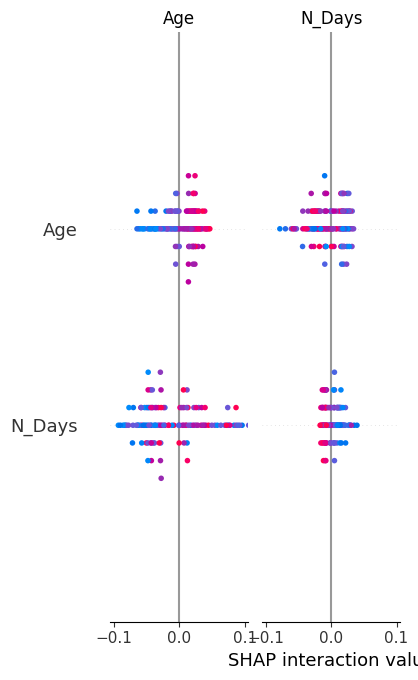

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report
import shap
from scipy.stats import spearmanr

# 1. Load dataset
# df = pd.read_csv("E:/Datasets/PBC dataset.csv")
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Data preprocessing
df = df.drop(['ID'], axis=1)
df['Status'] = df['Status'].apply(lambda x: 1 if x in ['C', 'D'] else 0)

# Separate features and target
X = df.drop('Status', axis=1)
y = df['Status']

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(include=['object']).columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns

# Create preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)])

# 2. Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. Preprocess data
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

# Get feature names
cat_feature_names = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols)
all_feature_names = list(num_cols) + list(cat_feature_names)

# 4. Train Random Forest classifier
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train_preprocessed, y_train)

# 5. Evaluate model
y_pred = rf.predict(X_test_preprocessed)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 6. SHAP Explanation
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test_preprocessed)

# For binary classification, we'll use SHAP values for class 1
if isinstance(shap_values, list):
    shap_values_class1 = np.array(shap_values[1])
else:
    shap_values_class1 = np.array(shap_values)

# 7. Compute Explainability Metrics

# (1) Sparsity: Number of features explaining 90% of SHAP importance
abs_shap = np.abs(shap_values_class1)
mean_shap = np.mean(abs_shap, axis=0)

# Ensure mean_shap is 1D before argsort
if mean_shap.ndim > 1:
    mean_shap = mean_shap.flatten()

sorted_idx = np.argsort(mean_shap)[::-1]
cumsum = np.cumsum(mean_shap[sorted_idx])
total = cumsum[-1]
num_features_90 = np.sum(cumsum <= 0.9 * total) + 1
sparsity = num_features_90

# Get top 5 features by SHAP importance
top5_idx = sorted_idx[:5]
top5_features = [all_feature_names[i] for i in top5_idx]

# (2) Fidelity/Comprehensiveness: Prediction change after removing top 5 features
def prediction_change_remove_features(model, X, features_to_remove_idx):
    X_modified = X.copy()
    # Ensure features_to_remove_idx is a 1D array of integers for advanced indexing
    X_modified[:, np.asarray(features_to_remove_idx).flatten()] = 0
    preds_orig = model.predict_proba(X)[:, 1]
    preds_mod = model.predict_proba(X_modified)[:, 1]
    return np.mean(np.abs(preds_orig - preds_mod))

fidelity = prediction_change_remove_features(rf, X_test_preprocessed, top5_idx)

# (3) Sufficiency: Prediction change using only top 5 features
def prediction_change_only_features(model, X, features_to_keep_idx):
    X_modified = np.zeros_like(X)
    # Ensure features_to_keep_idx is a 1D array of integers for advanced indexing
    X_modified[:, np.asarray(features_to_keep_idx).flatten()] = X[:, np.asarray(features_to_keep_idx).flatten()]
    preds_orig = model.predict_proba(X)[:, 1]
    preds_mod = model.predict_proba(X_modified)[:, 1]
    return np.mean(np.abs(preds_orig - preds_mod))

sufficiency = prediction_change_only_features(rf, X_test_preprocessed, top5_idx)

# (4) Consistency: Correlation of SHAP values with noise
noise = np.random.normal(size=mean_shap.shape)
consistency, _ = spearmanr(mean_shap, noise)

# 8. Print metrics
print("\nExplainability Metrics:")
print(f"Fidelity/Comprehensiveness (avg prediction change after removing top 5 features): {fidelity:.4f}")
print(f"Sparsity (features explaining 90% SHAP importance): {sparsity} out of {len(all_feature_names)}")
print(f"Consistency (correlation of SHAP values with noise): {consistency:.4f}")
print(f"Sufficiency (avg prediction change using only top 5 features): {sufficiency:.4f}")
print("\nTop 5 important features:")
for i, feat in enumerate(top5_features, 1):
    print(f"{i}. {feat}")

# 9. SHAP Summary Plot
shap.summary_plot(shap_values_class1, X_test_preprocessed, feature_names=all_feature_names)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Data Preparation
data = {
    'Model': ['Logistic Regression', 'SVM', 'Random Forest', 'MLP + SHAP + XAI', 'MLP + LIME+ XAI'],
    'Accuracy': [0.82, 0.86, 0.84, 0.75, 0.93],
    'Precision': [0.87, 0.89, 0.85, 0.77, 0.89],
    'Recall': [0.82, 0.86, 0.83, 0.75, 0.94],
    'F1-Score': [0.81, 0.85, 0.84, 0.75, 0.91],
    'Support': [56, 56, 56, 56, 126]
}

df = pd.DataFrame(data)

# Set style
sns.set(style='whitegrid')

# 2. Bar Plot
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
df_melt = df.melt(id_vars='Model', value_vars=metrics, var_name='Metric', value_name='Score')

plt.figure(figsize=(10, 6))
sns.barplot(x='Model', y='Score', hue='Metric', data=df_melt)
plt.title('Model Comparison - Bar Chart')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

# 3. Line Chart
plt.figure(figsize=(10, 6))
for metric in metrics:
    plt.plot(df['Model'], df[metric], marker='o', label=metric)

plt.title('Model Performance - Line Chart')
plt.xlabel('Model')
plt.ylabel('Score')
plt.xticks(rotation=30, ha='right')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Scatter Plot
plt.figure(figsize=(10, 6))
for metric in metrics:
    sns.scatterplot(x='Model', y=metric, data=df, label=metric)

plt.title('Model Metrics - Scatter Plot')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

# 5. Box Plot (showing distribution of metric scores per model)
plt.figure(figsize=(10, 6))
sns.boxplot(x='Model', y='Score', data=df_melt, palette='Set3')
plt.title('Model Metric Spread - Box Plot')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()



Generating PDP plots for top 5 SHAP features: Cholesterol, Bilirubin, Hepatomegaly_N, Hepatomegaly_Y, Albumin...
Could not generate PDP for feature 'Hepatomegaly_N' due to error: cannot reshape array of size 1 into shape (2)
Could not generate PDP for feature 'Hepatomegaly_Y' due to error: cannot reshape array of size 1 into shape (2)


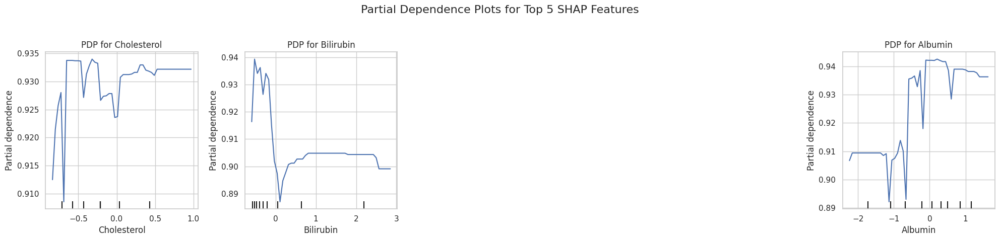

In [54]:
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay
import numpy as np

# Retrieve the model and preprocessed data from the notebook state
# Assuming 'rf' (RandomForestClassifier) and 'X_test_preprocessed' (numpy array)
# and 'all_feature_names' (list of strings) are available from previous cells.

# Top 5 SHAP features identified previously:
top5_shap_features = ['Cholesterol', 'Bilirubin', 'Hepatomegaly_N', 'Hepatomegaly_Y', 'Albumin']

print(f"\nGenerating PDP plots for top 5 SHAP features: {', '.join(top5_shap_features)}...")

# Create a figure with subplots for each feature
fig, axes = plt.subplots(nrows=1, ncols=len(top5_shap_features), figsize=(20, 5))
fig.suptitle('Partial Dependence Plots for Top 5 SHAP Features', fontsize=16)

for i, feature in enumerate(top5_shap_features):
    try:
        PartialDependenceDisplay.from_estimator(
            estimator=rf, # Your trained Random Forest model
            X=X_test_preprocessed, # Your preprocessed test data
            features=[feature], # Plot one feature at a time
            kind="average", # Show only the PDP curve
            feature_names=all_feature_names, # Use all feature names for correct axis labels
            grid_resolution=50,
            ax=axes[i],
            response_method='auto', # Use 'auto' response method
            target=1 # Explicitly specify the target class (1 for Cirrhosis)
        )
        axes[i].set_title(f'PDP for {feature}')
        axes[i].set_ylabel('Predicted Probability' if i == 0 else '') # Only label y-axis for the first plot
    except ValueError as e:
        print(f"Could not generate PDP for feature '{feature}' due to error: {e}")
        axes[i].set_visible(False) # Hide the subplot if an error occurs
        axes[i].set_title(f'PDP for {feature} (Error)')

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent suptitle overlap
plt.show()


Generating PDP plots for Cholesterol, Bilirubin...


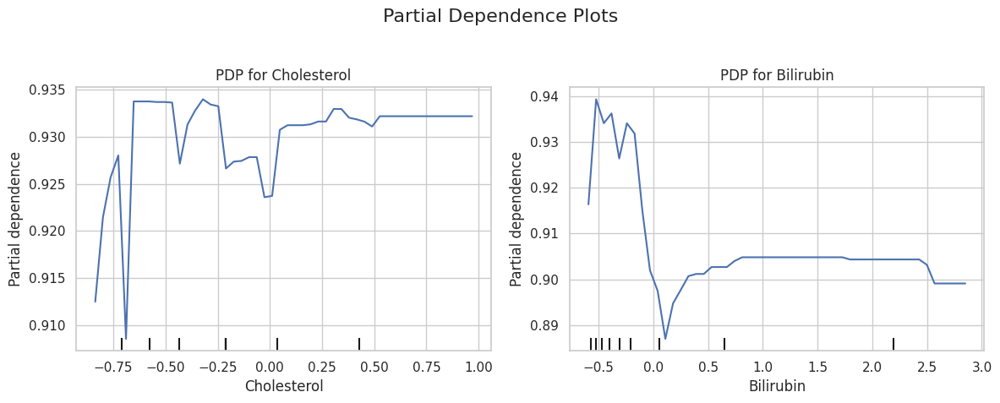

In [58]:
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay
import numpy as np

# Assuming 'rf' (RandomForestClassifier) and 'X_test_preprocessed' (numpy array)
# and 'all_feature_names' (list of strings) are available from previous cells.

features_to_plot = ['Cholesterol', 'Bilirubin']

print(f"\nGenerating PDP plots for {', '.join(features_to_plot)}...")

fig, axes = plt.subplots(nrows=1, ncols=len(features_to_plot), figsize=(12, 5))
fig.suptitle('Partial Dependence Plots', fontsize=16)

for i, feature in enumerate(features_to_plot):
    PartialDependenceDisplay.from_estimator(
        estimator=rf,
        X=X_test_preprocessed,
        features=[feature],
        kind="average",
        feature_names=all_feature_names,
        grid_resolution=50,
        ax=axes[i],
        response_method='predict_proba',
        target=1
    )
    axes[i].set_title(f'PDP for {feature}')
    axes[i].set_ylabel('Predicted Probability' if i == 0 else '')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

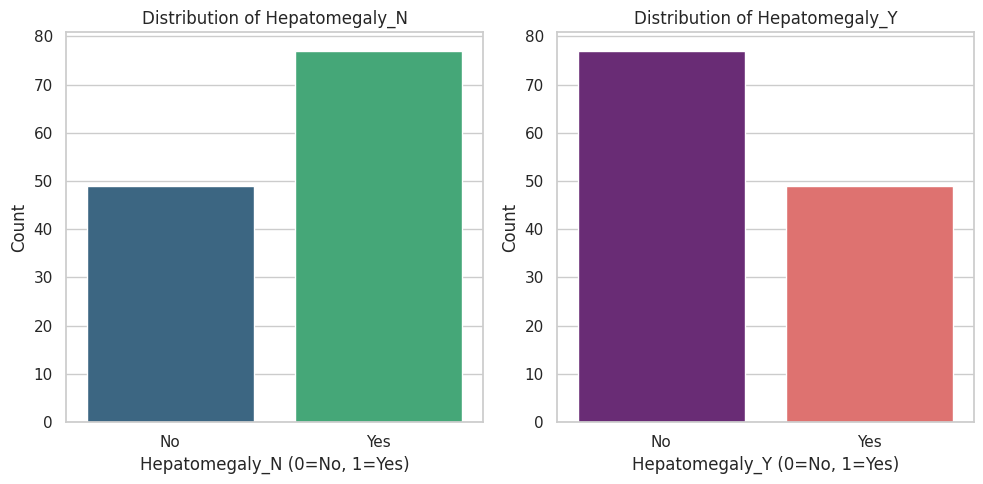

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assuming X_test_preprocessed and all_feature_names are available

# Extract the 'Hepatomegaly_N' and 'Hepatomegaly_Y' columns
hep_n_idx = all_feature_names.index('Hepatomegaly_N')
hep_y_idx = all_feature_names.index('Hepatomegaly_Y')

hep_n_data = X_test_preprocessed[:, hep_n_idx]
hep_y_data = X_test_preprocessed[:, hep_y_idx]

# Create a DataFrame for easier plotting
hep_df = pd.DataFrame({
    'Hepatomegaly_N': hep_n_data,
    'Hepatomegaly_Y': hep_y_data
})

plt.figure(figsize=(10, 5))

# Plot for Hepatomegaly_N
plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
sns.countplot(x='Hepatomegaly_N', data=hep_df, palette='viridis')
plt.title('Distribution of Hepatomegaly_N')
plt.xlabel('Hepatomegaly_N (0=No, 1=Yes)')
plt.ylabel('Count')
plt.xticks([0, 1], ['No', 'Yes']) # Label for clarity

# Plot for Hepatomegaly_Y
plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
sns.countplot(x='Hepatomegaly_Y', data=hep_df, palette='magma')
plt.title('Distribution of Hepatomegaly_Y')
plt.xlabel('Hepatomegaly_Y (0=No, 1=Yes)')
plt.ylabel('Count')
plt.xticks([0, 1], ['No', 'Yes']) # Label for clarity

plt.tight_layout()
plt.show()

In [56]:
import numpy as np
import pandas as pd

# Assuming df (original DataFrame) is available from earlier cells
# Assuming X_test_preprocessed and all_feature_names are available
# Assuming rf (trained RandomForestClassifier) is available

print("\n--- Investigation of Hepatomegaly_N and Hepatomegaly_Y ---")

# 1. The original 'Hepatomegaly' column was one-hot encoded and no longer exists in df.
#    We will directly inspect the preprocessed features.
# print(f"Original 'Hepatomegaly' unique values: {df['Hepatomegaly'].unique()}")

# 2. Find indices of 'Hepatomegaly_N' and 'Hepatomegaly_Y' in preprocessed features
hep_n_idx = all_feature_names.index('Hepatomegaly_N')
hep_y_idx = all_feature_names.index('Hepatomegaly_Y')

print(f"'Hepatomegaly_N' index in all_feature_names: {hep_n_idx}")
print(f"'Hepatomegaly_Y' index in all_feature_names: {hep_y_idx}")

# 3. Inspect unique values of these features in X_test_preprocessed
hep_n_values_test = X_test_preprocessed[:, hep_n_idx]
hep_y_values_test = X_test_preprocessed[:, hep_y_idx]

print(f"Unique values of 'Hepatomegaly_N' in X_test_preprocessed: {np.unique(hep_n_values_test)}")
print(f"Unique values of 'Hepatomegaly_Y' in X_test_preprocessed: {np.unique(hep_y_values_test)}")

# If one-hot encoded and original column had only one value, one of these might be constant (e.g., all 0s or all 1s)
# Let's verify if either column is constant in X_test_preprocessed
is_hep_n_constant = np.all(hep_n_values_test == hep_n_values_test[0])
is_hep_y_constant = np.all(hep_y_values_test == hep_y_values_test[0])

print(f"'Hepatomegaly_N' is constant in X_test_preprocessed: {is_hep_n_constant}")
print(f"'Hepatomegaly_Y' is constant in X_test_preprocessed: {is_hep_y_constant}")

# 4. Simulate prediction to check for constant output if a feature is varied
# This is more involved but conceptually what PDP does
# Create a dummy instance from X_test_preprocessed
sample_instance = X_test_preprocessed[0].copy()

# Vary 'Hepatomegaly_N' and predict (assuming its range is 0 to 1 as one-hot encoded)
variation_points = np.array([0, 1]) # Typically these would be unique values or a grid

print(f"\nSimulating predictions by varying 'Hepatomegaly_N' (index {hep_n_idx}):")
preds_hep_n = []
for val in variation_points:
    temp_instance = sample_instance.copy()
    temp_instance[hep_n_idx] = val
    # Ensure other Hepatomegaly columns are consistent (e.g., if N is 1, Y should be 0)
    if 'Hepatomegaly_Y' in all_feature_names and hep_y_idx != hep_n_idx:
        temp_instance[hep_y_idx] = 1 - val # If N is 1, Y is 0, and vice versa

    # predict_proba returns [prob_class_0, prob_class_1]
    prob_class1 = rf.predict_proba(temp_instance.reshape(1, -1))[0, 1]
    preds_hep_n.append(prob_class1)
    print(f"- 'Hepatomegaly_N' = {val}: Predicted Probability (Class 1) = {prob_class1:.4f}")

if np.all(np.isclose(preds_hep_n, preds_hep_n[0])):
    print("Result: Predictions are constant for varying 'Hepatomegaly_N'. This is likely why PDP failed.")
else:
    print("Result: Predictions vary for 'Hepatomegaly_N'. The issue might be elsewhere.")



print(f"\nSimulating predictions by varying 'Hepatomegaly_Y' (index {hep_y_idx}):")
preds_hep_y = []
for val in variation_points:
    temp_instance = sample_instance.copy()
    temp_instance[hep_y_idx] = val
    # Ensure other Hepatomegaly columns are consistent (e.g., if Y is 1, N should be 0)
    if 'Hepatomegaly_N' in all_feature_names and hep_n_idx != hep_y_idx:
        temp_instance[hep_n_idx] = 1 - val # If Y is 1, N is 0, and vice versa

    # predict_proba returns [prob_class_0, prob_class_1]
    prob_class1 = rf.predict_proba(temp_instance.reshape(1, -1))[0, 1]
    preds_hep_y.append(prob_class1)
    print(f"- 'Hepatomegaly_Y' = {val}: Predicted Probability (Class 1) = {prob_class1:.4f}")

if np.all(np.isclose(preds_hep_y, preds_hep_y[0])):
    print("Result: Predictions are constant for varying 'Hepatomegaly_Y'. This is likely why PDP failed.")
else:
    print("Result: Predictions vary for 'Hepatomegaly_Y'. The issue might be elsewhere.")


--- Investigation of Hepatomegaly_N and Hepatomegaly_Y ---
'Hepatomegaly_N' index in all_feature_names: 18
'Hepatomegaly_Y' index in all_feature_names: 19
Unique values of 'Hepatomegaly_N' in X_test_preprocessed: [0. 1.]
Unique values of 'Hepatomegaly_Y' in X_test_preprocessed: [0. 1.]
'Hepatomegaly_N' is constant in X_test_preprocessed: False
'Hepatomegaly_Y' is constant in X_test_preprocessed: False

Simulating predictions by varying 'Hepatomegaly_N' (index 18):
- 'Hepatomegaly_N' = 0: Predicted Probability (Class 1) = 0.9639
- 'Hepatomegaly_N' = 1: Predicted Probability (Class 1) = 0.9639
Result: Predictions are constant for varying 'Hepatomegaly_N'. This is likely why PDP failed.

Simulating predictions by varying 'Hepatomegaly_Y' (index 19):
- 'Hepatomegaly_Y' = 0: Predicted Probability (Class 1) = 0.9639
- 'Hepatomegaly_Y' = 1: Predicted Probability (Class 1) = 0.9639
Result: Predictions are constant for varying 'Hepatomegaly_Y'. This is likely why PDP failed.
